# DCD — Egli SGG unmixing

Interactive fitting of skewed generalized Gaussian (SGG) coercivity components to DCD curves (Egli, 2003, 2004).

## Input and output

- **Input:** field and moment/magnetization in two numerical columns. Field units may be specified; no mass normalization is applied.
- **Output:** component parameters, fitted DCD and spectra, comparison statistics, optional bootstrap intervals, PDF/PNG figures and tabulated results.
- **Directories:** `DCD_unmix_results/figures/` and `DCD_unmix_results/fit_data/` under the selected output parent.

## Workflow

1. Set model parameters and component bounds.
2. Select and load measurements; inspect the DCD curves.
3. Compare component counts if needed, then fit the selected model.
4. Run the optional bootstrap and export.

Example: `examples/DCD/processed_dcd/DCD_clean_magnetization/TA04-05-5s_500mT_back_unmix.back` (mT, A m²).

The fit uses the DCD curve rather than its derivative. The SGG median (`Bh`) and modal coercivity (`Bh_mode`) differ for asymmetric components. Model definitions and references follow below.

## Dependencies

`numpy`, `pandas`, `scipy`, `matplotlib`, `ipywidgets`; optional: `ipyfilechooser`.


In [1]:
"""Reusable adaptation of DCD_unmixing_joint: standalone notebook engine.
Original workflow: experimental-position derivative, bounded Gaussian mixtures,
multi-start fitting, DCD reconstruction and four-panel sample summaries.
"""
from pathlib import Path
from datetime import datetime, timezone
import copy, hashlib, json, re, warnings
import platform, scipy, matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.interpolate import UnivariateSpline
from scipy.integrate import cumulative_trapezoid
from scipy.stats import norm

try:
    from IPython.display import display
except ImportError:
    display = print

TRAPZ = getattr(np, 'trapezoid', np.trapz if hasattr(np, 'trapz') else None)
SOURCE_NOTEBOOK = 'DCD_unmixing_joint.ipynb (original workflow); independent Egli SGG implementation'

def locate_project_root(override=None):
    if override is not None:
        root = Path(override).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(f'Project directory does not exist: {root}')
        return root
    for root in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (root/'data'/'dcd_curves').is_dir():
            return root
    return None  # standalone notebook: files can be selected from anywhere

def sample_name(path):
    """Use the complete input basename consistently across projects."""
    return Path(path).stem

def validate_config(config,require_model=True):
    c = copy.deepcopy(config)
    c['fit_objective']='dcd'
    if require_model:
        if 'n_components' not in c or 'bh_bounds_mT' not in c:
            raise ValueError('Define K and Bh intervals in section 4 or 7 before fitting.')
        k = c['n_components']
        if not isinstance(k, (int, np.integer)) or not 1 <= k <= 8:
            raise ValueError('n_components must be an integer between 1 and 8')
        bounds = c['bh_bounds_mT']
        if len(bounds) < k:
            raise ValueError(f'{k} components require {k} Bh intervals')
        c['bh_bounds_mT'] = [tuple(map(float, b)) for b in bounds[:k]]
        for i, b in enumerate(c['bh_bounds_mT'], 1):
            if len(b) != 2 or not np.isfinite(b).all() or not 0 < b[0] < b[1]:
                raise ValueError(f'C{i}: Bh limits must be finite, positive and increasing')
        if any(c['bh_bounds_mT'][i][0] >= c['bh_bounds_mT'][i+1][0] for i in range(k-1)):
            raise ValueError('List component intervals in increasing coercivity order')
        if any(c['bh_bounds_mT'][i][1] > c['bh_bounds_mT'][i+1][0] for i in range(k-1)):
            warnings.warn('Bh intervals overlap: component labels may be ambiguous. Inspect the fitted centres.')
    if c['fit_mode'] not in ('independent', 'soft', 'shared'):
        raise ValueError("fit_mode: 'independent', 'soft' or 'shared'")
    if not set(c['coupled_parameters']).issubset({'Bh', 'DP', 'S'}):
        raise ValueError('Only Bh, DP and S can be coupled; component amounts remain sample-specific')
    if c['fit_mode'] != 'independent' and not c['coupled_parameters']:
        raise ValueError('Choose at least one parameter to couple, or use independent mode')
    if c['fit_mode'] != 'independent' and 'S' in c['coupled_parameters'] and not c['use_asymmetry']:
        raise ValueError('Enable asymmetry before coupling S, or remove S from coupled_parameters')
    if c['fit_mode'] == 'soft' and (not np.isfinite(c['similarity_strength']) or c['similarity_strength'] <= 0):
        raise ValueError('Soft mode requires a strictly positive similarity strength')
    if not .01 <= c['s_min'] < 1:
        raise ValueError('s_min must be at least 0.01 and below 1; S_max is fixed at 1')
    if len(c['dp_bounds']) != 2 or not 0 < c['dp_bounds'][0] < c['dp_bounds'][1]:
        raise ValueError('Invalid DP limits')
    if c['smoothing_s'] < 0 or c['grid_points'] < 50 or c['n_starts'] < 1 or c['max_nfev'] < 1:
        raise ValueError('Invalid smoothing, grid or optimizer settings')
    if c['spectrum_method'] not in ('absolute', 'signed'):
        raise ValueError("spectrum_method must be 'absolute' or 'signed'")
    return c

def build_spectrum(df, config, n_grid=450):
    """
    Calculate the coercivity spectrum from the experimental DCD points.

    Default sequence:
        measured M(log10 B)
        -> numerical derivative at the measured log10(B) positions
        -> absolute coercivity spectrum
        -> linear interpolation of the spectrum to the fitting grid

    Crucially, M is NOT densely interpolated before differentiation.

    If SMOOTH_BEFORE_GRADIENT=True, a smoothing spline is fitted to the
    experimental M(log10 B) values and evaluated at those same measured
    positions before calculating the numerical derivative.
    """
    x = df["logB"].to_numpy(dtype=float)
    y = df["M_norm"].to_numpy(dtype=float)

    order = np.argsort(x)
    x, y = x[order], y[order]

    # Require strictly increasing log-field coordinates.
    keep = np.concatenate(([True], np.diff(x) > 0))
    x, y = x[keep], y[keep]

    if len(x) < 5:
        raise ValueError("Too few unique field values to construct a) coercivity spectrum.")

    y_used = y.copy()

    if config['smooth']:
        if config['smoothing_s'] < 0:
            raise ValueError("SMOOTHING_SPLINE_S must be >= 0.")
        smoothing_spline = UnivariateSpline(
            x,
            y,
            s=float(config['smoothing_s']),
            k=min(3, len(x) - 1),
        )
        y_used = smoothing_spline(x)

    # Derivative calculated directly at the EXPERIMENTAL log-field positions.
    gradient_measured = np.abs(np.gradient(y_used, x)) if config['spectrum_method']=='absolute' else -np.gradient(y_used, x)
    if config['spectrum_method']=='absolute':
        gradient_measured = np.clip(gradient_measured, 0, None)

    # The regular grid is introduced only AFTER the derivative is known.
    x_grid = np.linspace(x.min(), x.max(), int(n_grid))
    spectrum_grid = np.interp(x_grid, x, gradient_measured)
    if config['spectrum_method']=='absolute':
        spectrum_grid = np.clip(spectrum_grid, 0, None)

    # DCD representation on the same grid, used only for plotting/export.
    m_grid = np.interp(x_grid, x, y_used)

    metadata = {
        "x_measured": x,
        "M_measured": y,
        "M_used_for_gradient": y_used,
        "gradient_measured": gradient_measured,
        "smoothed": bool(config['smooth']),
    }

    return x_grid, m_grid, spectrum_grid, metadata

def read_dcd(path, config):
    """Strict two-column reader; raw moments stay unchanged, including negatives."""
    raw_bytes = Path(path).read_bytes()
    text = raw_bytes.decode('latin-1')
    is_micromag = 'MicroMag' in text
    if is_micromag and not ('Remanence curves:' in text and 'DCD' in text.split('Remanence curves:', 1)[1][:40]):
        raise ValueError(f'{path.name}: MicroMag input is not a DCD curve')
    rows = []
    for line in text.splitlines():
        parts = re.split(r'[,;\s]+', line.strip())
        if len(parts) == 2:
            try:
                rows.append([float(v) for v in parts])
            except ValueError:
                pass
    if len(rows) < 8:
        raise ValueError(f'{path.name}: fewer than 8 numeric B,M pairs')
    data = np.asarray(rows, float)
    if not np.isfinite(data).all():
        raise ValueError(f'{path.name}: non-finite observations; edit explicitly')
    requested = config['field_unit']
    if requested == 'auto':
        if is_micromag and 'Hybrid SI' in text:
            unit = 'T'
        elif 'Field_mT' in text or 'B_mT' in text:
            unit = 'mT'
        else:
            raise ValueError(f'{path.name}: unknown field units; set field_unit explicitly')
    else:
        unit = requested
    factor = {'T':1000., 'mT':1., 'uT':.001}.get(unit)
    if factor is None:
        raise ValueError('field_unit must be auto, T, mT or uT')
    if is_micromag:
        B = -data[:, 0]*factor
        if abs(B[0]) < .01:
            B[0] = 0.
    else:
        B = data[:, 0]*factor
        if np.all(B[1:] < 0) and B[0] <= 0:
            B = -B  # reverse-field magnitude; never change moment signs
    if B[0] < 0 or not np.all(np.diff(B) > 0):
        raise ValueError(f'{path.name}: fields must be nonnegative and strictly increasing; no silent averaging')
    M = data[:, 1].copy()
    m0, mend = float(M[0]), float(M[-1])
    scale = max(abs(m0), abs(mend), np.finfo(float).tiny)
    if m0-mend <= 100*np.finfo(float).eps*scale:
        raise ValueError(f'{path.name}: insufficient decreasing DCD range')
    M_norm = (M-mend)/(m0-mend)
    B_log = B.copy()
    if B_log[0] == 0:
        B_log[0] = B_log[1]/2  # same near-zero convention as original notebook/MAX UnMix
    x_obs = np.log10(B_log)
    x, _, spectrum, metadata = build_spectrum(pd.DataFrame({'logB':x_obs,'M_norm':M_norm}),config,config['grid_points'])
    used = metadata['M_used_for_gradient']
    observed = metadata['gradient_measured']
    raw_signed = -np.gradient(M_norm, x_obs)
    raw_spectrum = np.abs(raw_signed) if config['spectrum_method'] == 'absolute' else raw_signed
    if not np.max(spectrum) > 0:
        raise ValueError(f'{path.name}: no positive coercivity spectrum')
    flags = []
    if m0 < 0 or mend > 0:
        flags.append('check DCD initial/final signs')
    if abs(mend+m0) > .05*max(abs(m0),np.finfo(float).tiny):
        flags.append('end moment is not antipodal to initial within 5%; endpoint normalization is conditional')
    if abs(m0) < 1e-7:
        flags.append('weak initial moment: inspect signal/noise')
    upward = int(np.sum(np.diff(M)>0))
    if upward:
        flags.append(f'{upward} upward moment steps')
    crossings = int(np.sum(M[:-1]*M[1:] < 0))
    if crossings != 1:
        flags.append(f'{crossings} sign crossings: no unique raw Bcr')
    return dict(name=sample_name(path), path=str(Path(path).resolve()), file=path.name,
                sha256=hashlib.sha256(raw_bytes).hexdigest(), field_unit=unit, B_original=B,
                B_for_log=B_log, M_raw=M, M_norm=M_norm, M_used=used, m0=m0, mend=mend,
                x_obs=x_obs, observed=observed, raw_spectrum=raw_spectrum,
                x=x, spectrum=spectrum, gmax=float(np.max(spectrum)), flags=flags)

# SGG family: Egli (2003), Eq. (7); applied by Egli (2004a). p fixed at 2.
# Positive interface parameter S=q (0<S<=1): low-coercivity tail, as in Egli examples.
from functools import lru_cache
from scipy.interpolate import CubicSpline
from scipy.special import roots_legendre

def _egli_right_transform(z, S):
    """Stable t=ln[(exp(-S*z)+exp(-z/S))/2] and |dt/dz|."""
    a=(S+1/S)/2; b=(1/S-S)/2
    t=np.logaddexp(-S*z,-z/S)-np.log(2.)
    d=a-b*np.tanh(b*z)
    return t,d

def _egli_transform(z, S):
    """Egli Eq.(1), q=S>0: t=ln[(exp(S*z)+exp(z/S))/2], dt/dz>0.

    Reflection reuses the numerically stable helper; no sample data are reflected.
    """
    return _egli_right_transform(-np.asarray(z),S)

@lru_cache(maxsize=1)
def _egli_shape_lookup():
    """Unit-scale standard deviation, reflected-mode and peak; deterministic quadrature.

    Integrate inverse-transform moments of the reflected branch against N(0,1).
    Reflection preserves SD and peak; egli_geometry reverses the mode sign. Split quadrature
    and invert the monotonic transform by bisection. No fitted data used.
    Cubic interpolation only accelerates scale/peak conversion; the evaluated
    curve itself always uses Egli's exact analytic equation with p=2.
    """
    grid=np.linspace(.01,1.,1981)
    nodes,w=roots_legendre(160)
    edges=[-12.,-np.log(2.),0.,12.]
    t=np.concatenate([(b-a)/2*nodes+(a+b)/2 for a,b in zip(edges[:-1],edges[1:])])
    weights=np.concatenate([(b-a)/2*w for a,b in zip(edges[:-1],edges[1:])])*norm.pdf(t)
    target=t[None,:];S=grid[:,None]
    extent=(np.abs(target)+np.log(2)+1)/S
    left=-extent;right=extent
    for _ in range(52):
        middle=(left+right)/2
        value,_=_egli_right_transform(middle,S)
        left=np.where(value>target,middle,left)
        right=np.where(value>target,right,middle)
    z=(left+right)/2
    mean=z@weights
    sd=np.sqrt((z*z)@weights-mean*mean)
    # Mode and median differ for asymmetric components.
    left=-2/grid;right=np.zeros_like(grid)
    a=(grid+1/grid)/2;b=(1/grid-grid)/2
    for _ in range(52):
        mid=(left+right)/2
        val,d=_egli_right_transform(mid,grid)
        tanh=np.tanh(b*mid)
        slope=val*d*d-b*b*(1-tanh*tanh)
        left=np.where(slope>0,mid,left)
        right=np.where(slope>0,right,mid)
    mode=(left+right)/2
    val,d=_egli_right_transform(mode,grid);peak=d*np.exp(-.5*val*val)
    sd[-1]=1.;mode[-1]=0.;peak[-1]=1.
    return tuple(CubicSpline(grid,v,extrapolate=False) for v in [sd,mode,peak])

def egli_geometry(dp,S):
    if not .01<=S<=1:raise ValueError('Egli S=q must satisfy 0.01 <= S <= 1')
    if S==1:return float(dp),0.,1.
    sd,mode,peak=_egli_shape_lookup()
    sigma=float(dp/sd(S))
    return sigma,-float(mode(S)),float(peak(S))

def component_curve(x,mu,dp,amp,gmax,S=1.):
    """Egli SGG p=2: true median Bh=10**mu, DP=std(log10 B), peak=amp*gmax."""
    if S==1:return amp*gmax*np.exp(-.5*((np.asarray(x)-mu)/dp)**2)
    sigma,mode,peak=egli_geometry(dp,S)
    z=(np.asarray(x)-mu)/sigma
    t,d=_egli_transform(z,S)
    return amp*gmax*d*np.exp(-.5*t*t)/peak

def unpack_params(p, config):
    return np.asarray(p).reshape(config['n_components'], 4 if config['use_asymmetry'] else 3)

def mixture_curve(x,p,sample,config):
    # The derivative is evaluated for diagnostics only; amplitudes are DCD steps.
    comps=[]
    for pars in unpack_params(p,config):
        mu,dp,amplitude=pars[:3];S=pars[3] if config['use_asymmetry'] else 1.
        sigma,_,peak=egli_geometry(dp,S)
        peak_height=amplitude*peak/(sigma*np.sqrt(2*np.pi))
        comps.append(component_curve(x,mu,dp,peak_height,1.,S))
    matrix=np.column_stack(comps)
    return matrix,matrix.sum(axis=1)

def component_survival(x,mu,dp,S=1.):
    """Analytic survival function of Egli Eq.(1), p=2, q=S>0."""
    sigma,_,_=egli_geometry(dp,S)
    z=(np.asarray(x)-mu)/sigma
    t=np.logaddexp(S*z,z/S)-np.log(2.)
    return norm.sf(t)

def measured_dcd_x(sample):
    """Use the exact B=0 limit for DCD fitting; log surrogate is plotting-only."""
    x=np.asarray(sample['x_obs'],float).copy()
    x[np.asarray(sample['B_original'])==0]=-np.inf
    return x

def dcd_target(sample,config):
    return np.asarray(sample['M_used'] if config['smooth'] else sample['M_norm'],float)

def dcd_transition(x,p,config):
    """Sum A_i * survival_i; A_i is full normalized DCD transition amplitude."""
    out=np.zeros_like(np.asarray(x),dtype=float)
    for pars in unpack_params(p,config):
        mu,dp,amplitude=pars[:3];S=pars[3] if config['use_asymmetry'] else 1.
        out+=amplitude*component_survival(x,mu,dp,S)
    return out

def dcd_model_at_measurements(sample,p,config,offset=None):
    transition=dcd_transition(measured_dcd_x(sample),p,config)
    if offset is None:
        # An unconstrained per-specimen affine reference, profiled exactly for SSE.
        offset=float(np.mean(dcd_target(sample,config)-transition))
    return transition+offset,float(offset)

def dcd_residual(sample,p,config):
    model,_=dcd_model_at_measurements(sample,p,config)
    return (model-dcd_target(sample,config))/np.sqrt(len(model))

def finish_dcd_optimizer(sample,optimizer,config):
    if optimizer.get('params') is not None:
        _,optimizer['dcd_offset']=dcd_model_at_measurements(sample,optimizer['params'],config)
    return optimizer

def parameter_bounds(config):
    lower, upper = [], []
    for lo,hi in config['bh_bounds_mT']:
        lower.extend([np.log10(lo),config['dp_bounds'][0],0.])
        upper.extend([np.log10(hi),config['dp_bounds'][1],100.])
        if config['use_asymmetry']:
            lower.append(config['s_min']); upper.append(1.)
    return np.array(lower), np.array(upper)

def _mu_guesses_inside_bounds(x, y, bh_bounds_mt):
    mus = []
    for lo_mt, hi_mt in bh_bounds_mt:
        lo, hi = np.log10(lo_mt), np.log10(hi_mt)
        mask = (x >= lo) & (x <= hi)
        if np.any(mask):
            xx, yy = x[mask], y[mask]
            mu = xx[np.argmax(yy)]
            eps = max((hi-lo)*1e-4, 1e-8)
            mu = np.clip(mu, lo+eps, hi-eps)
        else:
            mu = 0.5*(lo+hi)
        mus.append(mu)
    return np.asarray(mus, float)

def initial_params(sample, config):
    p = []
    mus = _mu_guesses_inside_bounds(sample['x'],sample['spectrum'],config['bh_bounds_mT'])
    for mu in mus:
        p.extend([mu,.22,1/config['n_components']])
        if config['use_asymmetry']:
            p.append(.95)
    lower,upper = parameter_bounds(config)
    return np.clip(p,lower+1e-8,upper-1e-8)

def _stable_seed(name, seed):
    return (int(hashlib.sha256(name.encode()).hexdigest()[:8],16)+int(seed)) % (2**32)

def _starts(sample,config):
    lower,upper = parameter_bounds(config)
    rng = np.random.default_rng(_stable_seed(sample['name'],config['random_seed']))
    first = initial_params(sample,config)
    starts = [first]
    for _ in range(config['n_starts']-1):
        p = first.copy().reshape(config['n_components'],-1)
        for i,b in enumerate(config['bh_bounds_mT']):
            p[i,0] = rng.uniform(np.log10(b[0]),np.log10(b[1]))
            p[i,1] *= np.exp(rng.normal(0,.35))
            p[i,2] = rng.uniform(.15,1.)
            if config['use_asymmetry']:
                p[i,3] = rng.uniform(config['s_min'],1.)
        starts.append(np.clip(p.ravel(),lower+1e-8,upper-1e-8))
    return starts

def fit_one_sample(sample, config):
    """Independent multi-start: stable seed by specimen, independent of batch order."""
    lower,upper = parameter_bounds(config)
    def residual(p):
        return dcd_residual(sample,p,config)
    runs = []
    best = None
    for index,start in enumerate(_starts(sample,config),1):
        out = least_squares(residual,start,bounds=(lower,upper),x_scale='jac',max_nfev=config['max_nfev'])
        score = float(out.fun@out.fun)
        runs.append(dict(start=index,objective=score,success=bool(out.success),nfev=int(out.nfev)))
        if best is None or score < best[0]:
            best = score,out
    return finish_dcd_optimizer(sample,dict(params=best[1].x,success=bool(best[1].success),message=best[1].message,
                nfev=int(best[1].nfev),starts=runs),config)

def _joint_fit(samples, independent, config):
    """Soft coupling or exact sharing; amplitudes always remain sample-specific."""
    lower_one,upper_one = parameter_bounds(config)
    step = 4 if config['use_asymmetry'] else 3
    names = ['Bh','DP','P']+(['S'] if config['use_asymmetry'] else [])
    shared = set(config['coupled_parameters']) if config['fit_mode']=='shared' else set()
    lookup, keys, lower, upper, values = {}, [], [], [], []
    for si,fit in enumerate(independent):
        for j in range(len(fit['params'])):
            key = (-1 if names[j%step] in shared else si,j)
            if key not in lookup:
                lookup[key]=len(keys);keys.append(key)
                lower.append(lower_one[j]);upper.append(upper_one[j])
                values.append(float(np.mean([v['params'][j] for v in independent])) if key[0]==-1 else fit['params'][j])
    lower,upper = np.array(lower),np.array(upper)
    indices = np.array([[lookup[(-1 if names[j%step] in shared else si,j)] for j in range(len(lower_one))] for si in range(len(samples))])
    def expand(theta):
        return theta[indices]
    def objective(theta):
        blocks = expand(theta)
        residual = [dcd_residual(s,p,config) for s,p in zip(samples,blocks)]
        if config['fit_mode']=='soft':
            pars = blocks.reshape(len(samples),config['n_components'],step)
            scales = {'Bh':.10,'DP':.08,'S':.10}
            for name in config['coupled_parameters']:
                if name not in names:
                    continue
                v = pars[:,:,names.index(name)]
                residual.append((np.sqrt(config['similarity_strength'])*(v-v.mean(axis=0))/scales[name]).ravel())
        return np.concatenate(residual)
    rng = np.random.default_rng(config['random_seed']+741)
    first = np.clip(values,lower+1e-8,upper-1e-8)
    candidates = [first]+[np.clip(first+rng.normal(0,.03,len(first))*(upper-lower),lower+1e-8,upper-1e-8) for _ in range(config['n_starts']-1)]
    best = None; runs=[]
    for index,start in enumerate(candidates,1):
        out = least_squares(objective,start,bounds=(lower,upper),x_scale='jac',max_nfev=config['max_nfev'])
        score = float(out.fun@out.fun)
        runs.append(dict(start=index,objective=score,success=bool(out.success),nfev=int(out.nfev)))
        if best is None or score<best[0]:best=score,out
    blocks=expand(best[1].x)
    return [finish_dcd_optimizer(s,dict(params=p,success=bool(best[1].success),message=best[1].message,nfev=int(best[1].nfev),starts=runs),config) for s,p in zip(samples,blocks)]

def reconstruct_dcd_from_spectrum(x, g):
    integ = cumulative_trapezoid(g, x, initial=0)
    if integ[-1] <= 0:
        return np.ones_like(x)
    return 1 - integ / integ[-1]


def summarize_fit(sample, optimizer, config):
    p=optimizer['params'];components,model=mixture_curve(sample['x'],p,sample,config)
    obs_components,obs_model=mixture_curve(sample['x_obs'],p,sample,config)
    dcd_obs,offset=dcd_model_at_measurements(sample,p,config,optimizer.get('dcd_offset'))
    dcd_grid=offset+dcd_transition(sample['x'],p,config)
    endpoints=measured_dcd_x(sample)[[0,-1]]
    window_areas=np.array([par[2]*np.ptp(component_survival(endpoints,par[0],par[1],par[3] if config['use_asymmetry'] else 1.)) for par in unpack_params(p,config)])
    if not np.isfinite(window_areas).all() or window_areas.sum()<=0:
        raise ValueError('Model has no finite positive area in the measured window; revise Bh limits')
    fractions=window_areas/window_areas.sum()
    rows=[];full_areas=[]
    for i,par in enumerate(unpack_params(p,config)):
        mu,dp,amp=par[:3];S=float(par[3]) if config['use_asymmetry'] else 1.
        sigma,mode_z,peak=egli_geometry(dp,S)
        full_area=float(amp);full_areas.append(full_area)
        lo,hi=config['bh_bounds_mT'][i];flags=[]
        if mu-np.log10(lo)<.02*np.log10(hi/lo):flags.append('Bh near lower bound')
        if np.log10(hi)-mu<.02*np.log10(hi/lo):flags.append('Bh near upper bound')
        if min(dp-config['dp_bounds'][0],config['dp_bounds'][1]-dp)<.02*np.ptp(config['dp_bounds']):flags.append('DP near bound')
        if amp<.001:flags.append('near-zero DCD transition amplitude')
        if amp>98:flags.append('DCD amplitude near upper numerical bound')
        if config['use_asymmetry'] and S-config['s_min']<.02*(1-config['s_min']):flags.append('S near lower bound')
        capture=float(window_areas[i]/full_area) if full_area>0 else 0.
        if capture<.9:flags.append('component tail outside measured field window')
        rows.append(dict(Sample=sample['name'],Component=i+1,Bh_mT=float(10**mu),log10_Bh=float(mu),
                         Bh_mode_mT=float(10**(mu+sigma*mode_z)),DP=float(dp),Sigma_Egli=float(sigma),
                         q_Egli=S,p_Egli=2.,P_peak=float(amp*peak/(sigma*np.sqrt(2*np.pi))),Amplitude_DCD=float(amp),DCD_offset=offset,S=S,
                         Contribution_fraction=float(fractions[i]),**{'Contribution_%':float(100*fractions[i])},
                         Window_capture_fraction=capture,Bh_min_allowed_mT=lo,Bh_max_allowed_mT=hi,
                         Bound_warning='; '.join(flags)))
    for row,area in zip(rows,full_areas):row['Contribution_full_model_%']=float(100*area/sum(full_areas))
    metrics=dict(Sample=sample['name'],Fit_mode=config['fit_mode'],Fit_objective='DCD smoothed' if config['smooth'] else 'DCD measured',
                 Model_version='Egli_SGG_p2_DCD_v4',DCD_offset=offset,
                 RMSE_DCD_target=float(np.sqrt(np.mean((dcd_target(sample,config)-dcd_obs)**2))),Optimizer_success=optimizer['success'],
                 Optimizer_message=str(optimizer['message']),N_measured=len(sample['B_original']),
                 RMSE_spectrum_measured=float(np.sqrt(np.mean((sample['observed']-obs_model)**2))),
                 RMSE_DCD_normalized=float(np.sqrt(np.mean((sample['M_norm']-dcd_obs)**2))),
                 N_components=config['n_components'],Input_warnings='; '.join(sample['flags']))
    measured=dict(B_original_mT=sample['B_original'],B_for_log_mT=sample['B_for_log'],
                  Signal_original_input_units=sample['M_raw'],DCD_normalized=sample['M_norm'],
                  DCD_fit_target=dcd_target(sample,config),DCD_smoothed=sample['M_used'],DCD_target_residual=dcd_target(sample,config)-dcd_obs,
                  DCD_raw_residual=sample['M_norm']-dcd_obs,Spectrum_raw=sample['raw_spectrum'],
                  Spectrum_fitted_data=sample['observed'],Spectrum_model=obs_model,
                  Spectrum_residual=sample['observed']-obs_model,DCD_model_normalized=dcd_obs,
                  Signal_model_input_units=sample['mend']+(sample['m0']-sample['mend'])*dcd_obs)
    for i in range(config['n_components']):measured[f'C{i+1}_spectrum']=obs_components[:,i]
    return dict(sample=sample,params=p,components=components,model=model,dcd_grid=dcd_grid,
                table=pd.DataFrame(rows),metrics=metrics,measured=pd.DataFrame(measured),
                optimizer=optimizer,config=copy.deepcopy(config))

def fit_samples(samples,config,progress=print):
    c=validate_config(config)
    if not samples:raise ValueError('Select at least one specimen')
    independent=[]
    for i,sample in enumerate(samples,1):
        if progress:progress(f'[{i}/{len(samples)}] {sample["name"]}: independent multi-start')
        independent.append(fit_one_sample(sample,c))
    if len(samples)>1 and c['fit_mode']!='independent':
        if progress:progress(f'Applying {c["fit_mode"]} coupling to {c["coupled_parameters"]} ...')
        optimizers=_joint_fit(samples,independent,c)
    else:optimizers=independent
    return [summarize_fit(s,o,c) for s,o in zip(samples,optimizers)]

def style_axis(ax):
    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
    ax.tick_params(direction='out');ax.grid(alpha=.12,lw=.5)

def make_sample_summary_figure(fit):
    """Four panels with component-matched colors and axis-sized parameter text."""
    import textwrap
    sample=fit['sample'];config=fit['config'];measured=fit['measured']
    uncertainty=fit.get('uncertainty');bands=uncertainty['bands'] if uncertainty is not None else {}
    colors=plt.rcParams['axes.prop_cycle'].by_key().get('color',['#1f77b4'])
    colors=[colors[i%len(colors)] for i in range(config['n_components'])]
    # Size the lower row to its content.
    blocks=[('d)  Component parameters','black'),
            (f"Mode: {config['fit_mode']}. Bh = median; Bpeak = mode; P = measured-window contribution.",'black')]
    for _,row in fit['table'].iterrows():
        color=colors[int(row.Component)-1]
        lines=[f"C{int(row.Component)}: Bh {row.Bh_mT:.2f} mT | Bpeak {row.Bh_mode_mT:.2f} mT",
               f"DP {row.DP:.3f} | S {row.S:.3f} | P {row['Contribution_%']:.1f}%"]
        if uncertainty is not None and row.get('Bootstrap_CI_available',False):
            lines.append(f"CI: Bh [{row.Bh_mT_CI_low:.2f}, {row.Bh_mT_CI_high:.2f}] mT; DP [{row.DP_CI_low:.3f}, {row.DP_CI_high:.3f}]")
            lines.append(f"S [{row.S_CI_low:.3f}, {row.S_CI_high:.3f}]; P [{row['Contribution_%_CI_low']:.1f}, {row['Contribution_%_CI_high']:.1f}]%")
        if row.Bound_warning:lines.append('CHECK: '+str(row.Bound_warning))
        blocks.append(('\n'.join(lines),color))
    if uncertainty is not None:
        diag=uncertainty['diagnostics']
        blocks.append((f"Bootstrap: {diag['successful_refits']}/{diag['requested']} accepted; {uncertainty['settings']['ci_percent']:g}% intervals.",'black'))
        if not diag['intervals_available']:blocks.append(('CHECK: insufficient accepted refits; CI withheld.','black'))
    blocks.append((f"RMSE DCD (raw data): {fit['metrics']['RMSE_DCD_normalized']:.4g}",'black'))
    if config.get('smooth',False):blocks.append((f"RMSE DCD (fit target): {fit['metrics']['RMSE_DCD_target']:.4g}",'black'))
    if not fit['metrics']['Optimizer_success']:blocks.append(('CHECK: optimizer did not converge.','black'))
    if sample['flags']:blocks.append(('Input: '+'; '.join(sample['flags']),'black'))
    blocks=[('\n'.join(textwrap.fill(line,68,subsequent_indent='  ') for line in text.splitlines()),color)
            for text,color in blocks]
    #blocks.insert(2,(f"Objective: {fit['metrics'].get('Fit_objective','legacy spectrum fit')}.",'black'))
    nlines=sum(text.count('\n')+1.22 for text,color in blocks)
    # Resolve named Matplotlib font sizes exactly as the axes do.
    from matplotlib.font_manager import FontProperties
    fontsize=FontProperties(size=plt.rcParams['axes.labelsize']).get_size_in_points()
    lower_height=max(2.8,nlines*fontsize*1.32/72+.30)
    top_height=4.25
    fig=plt.figure(figsize=(12.6,top_height+lower_height+1.0),constrained_layout=True)
    grid=fig.add_gridspec(2,2,height_ratios=[top_height,lower_height],width_ratios=[1.25,1.])
    spectrum_ax=fig.add_subplot(grid[0,0]);residual_ax=fig.add_subplot(grid[1,0],sharex=spectrum_ax)
    dcd_ax=fig.add_subplot(grid[0,1]);info_ax=fig.add_subplot(grid[1,1]);info_ax.axis('off')
    field=10**sample['x'];observed_field=sample['B_for_log']
    spectrum_ax.plot(observed_field,sample['raw_spectrum'],'.',color='.65',ms=3,label='DCD gradient',zorder=4)
    if config.get('smooth',config.get('smooth_before_gradient',False)):
        spectrum_ax.plot(observed_field,sample['observed'],'.',color='.25',ms=3,label='Smoothed gradient')
    for j,color in enumerate(colors):
        spectrum_ax.plot(field,fit['components'][:,j],color=color,lw=1.5,ls='--',label=f'C{j+1}')
    spectrum_ax.plot(field,fit['model'],color='#d58332',lw=2,label='Total model')
    for lo,hi in config['bh_bounds_mT']:
        spectrum_ax.axvline(lo,color='.8',ls=':',lw=.5);spectrum_ax.axvline(hi,color='.8',ls=':',lw=.5)
    spectrum_ax.set(xscale='log',ylabel='Normalized DCD gradient',title='a)  Coercivity spectrum')
    if bands:
        label=f"{uncertainty['settings']['ci_percent']:g}% bootstrap CI"
        spectrum_ax.fill_between(field,bands['spectrum_low'],bands['spectrum_high'],color='#d58332',alpha=.18,label=label)
        for j,color in enumerate(colors):
            spectrum_ax.fill_between(field,bands['components_low'][:,j],bands['components_high'][:,j],color=color,alpha=.10)
    spectrum_ax.legend(fontsize=max(8,fontsize-2),ncol=1,frameon=False,loc='upper left')
    target=measured['DCD_fit_target'].to_numpy() if 'DCD_fit_target' in measured else sample['M_norm']
    residual_ax.plot(observed_field,target-measured.DCD_model_normalized,'o-',ms=2.5,lw=.8,color='.35')
    residual_ax.axhline(0,color='.6',lw=.6)
    residual_ax.set(xscale='log',xlabel='Reverse-field magnitude (mT)',ylabel='DCD residual',title='b)  DCD')
    dcd_ax.plot(observed_field,sample['M_norm'],'o',ms=2.8,mfc='white',mew=.7,color='.35',label='Observed DCD')
    if config.get('smooth',False):dcd_ax.plot(observed_field,sample['M_used'],'-',color='#526b9c',lw=1.4,label='Smoothed DCD (fit target)')
    dcd_ax.plot(field,fit['dcd_grid'],color='#d58332',lw=1.5,label='Fitted DCD')
    dcd_ax.set(xscale='log',xlabel='Reverse-field magnitude (mT)',ylabel='Normalized DCD',title='c)  DCD fit')
    if bands:dcd_ax.fill_between(field,bands['dcd_low'],bands['dcd_high'],color='#d58332',alpha=.18,label=label)
    dcd_ax.legend(fontsize=max(8,fontsize-2),frameon=False, loc='lower left')
    consumed=0.
    for text,color in blocks:
        info_ax.text(0,1-consumed/nlines,text,va='top',transform=info_ax.transAxes,
                     fontsize=fontsize,color=color,linespacing=1.22)
        consumed+=text.count('\n')+1.22
    for axis in (spectrum_ax,residual_ax,dcd_ax):style_axis(axis)
    fig.suptitle(f"DCD coercivity unmixing: {sample['name']}",fontsize=fontsize+2)
    return fig

def _json_clean(value):
    if isinstance(value,dict):return {str(k):_json_clean(v) for k,v in value.items()}
    if isinstance(value,(tuple,list)):return [_json_clean(v) for v in value]
    if isinstance(value,np.ndarray):return _json_clean(value.tolist())
    if isinstance(value,(np.integer,)):return int(value)
    if isinstance(value,(np.floating,float)):return float(value) if np.isfinite(value) else None
    if isinstance(value,Path):return str(value)
    if isinstance(value,np.bool_):return bool(value)
    return value

# All analyses share exactly two output folders; no per-specimen/run directories.
_DATA_SUFFIXES = ('_fit.json','_fit.txt','_components.csv','_measured_points.csv','_model_curves.csv',
    '_bootstrap_CI.csv','_bootstrap_replicates.csv','_bootstrap_refits.csv','_bootstrap_settings.json',
    '_bootstrap_curve_bands.csv','_component_count_comparison.csv','_component_count_per_sample.csv',
    '_comparison_candidates.json')

def _export_basename(value):
    """Preserve the input filename stem, including spaces and Unicode; reject paths."""
    name=str(value)
    if not name or name in ('.','..') or '/' in name or '\\' in name or any(ord(c)<32 for c in name):
        raise ValueError('Output name must be a filename base, not a directory/path.')
    return name

def _output_paths(parent,name):
    return [parent/'figures'/f'{name}.pdf',parent/'figures'/f'{name}.png']+[
        parent/'fit_data'/f'{name}{suffix}' for suffix in _DATA_SUFFIXES]

def _bootstrap_flat(fit,name,out):
    u=fit.get('uncertainty')
    if u is None:return
    u['summary'].to_csv(out/f'{name}_bootstrap_CI.csv',index=False)
    u['raw'].to_csv(out/f'{name}_bootstrap_replicates.csv',index=False)
    u['refits'].to_csv(out/f'{name}_bootstrap_refits.csv',index=False)
    meta={k:u[k] for k in ['settings','diagnostics','baseline_signature']}
    (out/f'{name}_bootstrap_settings.json').write_text(json.dumps(_json_clean(meta),indent=2,allow_nan=False))
    b=u['bands']
    if b:
        table=dict(B_mT=10**fit['sample']['x'],Spectrum_CI_low=b['spectrum_low'],Spectrum_CI_high=b['spectrum_high'],
            DCD_CI_low=b['dcd_low'],DCD_CI_high=b['dcd_high'])
        for j in range(fit['config']['n_components']):
            table[f'C{j+1}_CI_low']=b['components_low'][:,j]
            table[f'C{j+1}_CI_high']=b['components_high'][:,j]
        pd.DataFrame(table).to_csv(out/f'{name}_bootstrap_curve_bands.csv',index=False)

def export_results(fits,project_root=None,output_parent=None,output_names=None,output_tag='',
                   overwrite=False,selection_label=None,comparison=None):
    """Accumulate files in figures/ and fit_data/. Default base = full input stem.

    No per-run or per-specimen directory is created. Existing bases receive __v02,
    __v03, ... unless overwrite=True. All figure/data files for a fit share the
    same resolved base. Output names may be overridden by input filename or ID.
    A temporary staging directory is removed before returning; no intermediate
    analysis folders remain. Point estimates and uncertainty are never refitted.
    """
    if not fits:raise ValueError('No final fits to save.')
    check_bootstrap_matches(fits)
    parent=Path(output_parent) if output_parent is not None else resolve_output_parent(project_root)
    parent=parent.expanduser().resolve()
    names={};reserved=set();overrides=output_names or {}
    for fit in fits:
        source=fit['sample']['file'];identifier=fit['sample']['name']
        base=overrides.get(source,overrides.get(identifier,Path(source).stem))
        base=_export_basename(base)
        if output_tag:base=_export_basename(base+'__'+str(output_tag))
        candidate=base;version=2
        while candidate.casefold() in reserved or (not overwrite and any(f.exists() for f in _output_paths(parent,candidate))):
            candidate=f'{base}__v{version:02d}';version+=1
        reserved.add(candidate.casefold());names[identifier]=candidate
    created=datetime.now(timezone.utc).isoformat()
    group=[dict(sample=f['sample']['name'],input_file=f['sample']['file'],sha256=f['sample']['sha256'],
                output_base=names[f['sample']['name']]) for f in fits]
    parent.mkdir(parents=True,exist_ok=True)
    # Prepare every file first, then publish the completed outputs into two folders.
    import tempfile
    with tempfile.TemporaryDirectory(prefix='.dcd_export_',dir=parent) as temporary:
        staging=Path(temporary);figs=staging/'figures';data=staging/'fit_data'
        figs.mkdir();data.mkdir()
        for fit in fits:
            name=names[fit['sample']['name']]
            fit['table'].to_csv(data/f'{name}_components.csv',index=False)
            fit['measured'].to_csv(data/f'{name}_measured_points.csv',index=False,float_format='%.16e')
            grid=dict(B_mT=10**fit['sample']['x'],log10_B=fit['sample']['x'],
                Spectrum_observed=fit['sample']['spectrum'],Spectrum_model=fit['model'],DCD_model_normalized=fit['dcd_grid'])
            for j in range(fit['config']['n_components']):grid[f'C{j+1}_spectrum']=fit['components'][:,j]
            pd.DataFrame(grid).to_csv(data/f'{name}_model_curves.csv',index=False,float_format='%.16e')
            # Self-contained snapshot for exact future replotting: no raw files needed.
            payload={k:fit[k] for k in ['sample','config','params','optimizer','metrics','components','model','dcd_grid']}
            payload['table']=fit['table'].to_dict('records')
            payload['measured']=fit['measured'].to_dict('records')
            payload['uncertainty_status']=fit.get('uncertainty_status','not calculated')
            u=fit.get('uncertainty')
            if u is not None:
                payload['uncertainty']={k:u[k] for k in ['settings','diagnostics','baseline_signature','bands']}
                payload['uncertainty']['summary']=u['summary'].to_dict('records')
            info=dict(export_schema='DCD_flat_v2',created_utc=created,output_base=name,
                source_notebook=SOURCE_NOTEBOOK,model_version='Egli_SGG_p2_DCD_v4',
                model_reference='Egli (2004) Part 1, section 4.2 Eq.(1), p=2, q=S>0',
                selection=selection_label,analysis_group=group,
                software_versions=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,
                    scipy=scipy.__version__,matplotlib=matplotlib.__version__),
                figure_files=[f'../figures/{name}.pdf',f'../figures/{name}.png'],fit_payload=payload)
            (data/f'{name}_fit.json').write_text(json.dumps(_json_clean(info),indent=2,allow_nan=False),encoding='utf-8')
            summary=fit['table'][['Component','Bh_mT','Bh_mode_mT','DP','S','Contribution_%','Bound_warning']].to_string(index=False)
            text=f'Input: {fit["sample"]["file"]}\nOutput base: {name}\nMode: {fit["config"]["fit_mode"]}\n'+summary
            if u is not None:text+='\n\nBootstrap intervals:\n'+u['summary'].to_string(index=False)
            (data/f'{name}_fit.txt').write_text(text,encoding='utf-8')
            _bootstrap_flat(fit,name,data)
            if comparison is not None:
                comparison['table'].to_csv(data/f'{name}_component_count_comparison.csv',index=False)
                comparison['per_sample'].to_csv(data/f'{name}_component_count_per_sample.csv',index=False)
                candidates={str(k):[dict(sample=f['sample']['name'],parameters=f['params'],settings=f['config'],
                    optimizer=f['optimizer']) for f in group_fits] for k,group_fits in comparison['fits_by_k'].items()}
                (data/f'{name}_comparison_candidates.json').write_text(json.dumps(_json_clean(candidates),indent=2,allow_nan=False))
            fig=make_sample_summary_figure(fit)
            try:
                fig.savefig(figs/f'{name}.png',dpi=180)
                pdf=figs/f'{name}.pdf';fig.savefig(pdf)
                if not pdf.read_bytes().rstrip().endswith(b'%%EOF'):raise RuntimeError('Incomplete PDF export')
            finally:plt.close(fig)
        (parent/'figures').mkdir(exist_ok=True);(parent/'fit_data').mkdir(exist_ok=True)
        emitted={str(f.relative_to(staging)) for sub in ['figures','fit_data'] for f in (staging/sub).iterdir()}
        for sub in ['figures','fit_data']:
            for file in (staging/sub).iterdir():file.replace(parent/sub/file.name)
        if overwrite:
            for name in names.values():
                for old in _output_paths(parent,name):
                    if old.exists() and str(old.relative_to(parent)) not in emitted:
                        old.unlink()  # only this base's known generated outputs
    for fit in fits:
        print(f'{fit["sample"]["file"]} -> figures/{names[fit["sample"]["name"]]}.pdf / .png; fit_data/{names[fit["sample"]["name"]]}_*')
    return parent

def load_saved_fit(json_path):
    """Restore an exported snapshot for make_sample_summary_figure; no raw input required."""
    path=Path(json_path);info=json.loads(path.read_text(encoding='utf-8'))
    if info.get('export_schema') not in ('DCD_flat_v1','DCD_flat_v2'):raise ValueError('Unsupported fit export schema')
    fit=info['fit_payload']
    for k in ['params','components','model','dcd_grid']:fit[k]=np.asarray(fit[k],float)
    for k in ['B_original','B_for_log','M_raw','M_norm','M_used','x_obs','observed','raw_spectrum','x','spectrum']:
        if k in fit['sample']:fit['sample'][k]=np.asarray(fit['sample'][k],float)
    fit['table']=pd.DataFrame(fit['table']);fit['measured']=pd.DataFrame(fit['measured'])
    if fit.get('uncertainty'):
        u=fit['uncertainty'];u['summary']=pd.DataFrame(u['summary'])
        u['bands']={k:np.asarray(v,float) for k,v in u['bands'].items()}
        base=info['output_base']
        for key,suffix in [('raw','_bootstrap_replicates.csv'),('refits','_bootstrap_refits.csv')]:
            file=path.with_name(base+suffix)
            u[key]=pd.read_csv(file) if file.exists() and file.stat().st_size>1 else pd.DataFrame()
    check_bootstrap_matches([fit])
    return fit



# Model comparison and fitting.
import tempfile
from scipy.signal import find_peaks

def resolve_output_parent(project_root=None, notebook_dir=None, output_override=None):
    if output_override is not None:
        return Path(output_override).expanduser().resolve()
    if project_root is not None:
        processed = Path(project_root)/'data/dcd_curves/processed_dcd'
        if processed.is_dir():
            return processed/'unmixing'
    return Path(notebook_dir or Path.cwd()).expanduser().resolve()/'DCD_unmix_results'

def uploaded_items(value):
    if isinstance(value, dict):
        return [(name, bytes(meta['content'])) for name, meta in value.items()]
    return [(item['name'], bytes(item['content'])) for item in (value or [])]

def load_selected_inputs(paths, upload_value, config):
    """Read explicit paths OR uploads; temporary upload copies are removed immediately."""
    items = uploaded_items(upload_value)
    if paths and items:
        raise ValueError('Use FILE_PATHS or uploads, not both (avoid duplicate experiments).')
    samples=[]
    if paths:
        samples=[read_dcd(Path(p).expanduser().resolve(), config) for p in paths]
    elif items:
        with tempfile.TemporaryDirectory(prefix='dcd_inputs_') as tmp:
            for index,(name,content) in enumerate(items):
                folder=Path(tmp)/str(index);folder.mkdir()
                path=folder/Path(name.replace('\\','/')).name
                path.write_bytes(content)
                sample=read_dcd(path,config)
                sample['path']='uploaded:'+sample['file']
                samples.append(sample)
    if len({s['name'] for s in samples})!=len(samples):
        raise ValueError('Duplicate specimen names: select only one experiment per specimen, or rename deliberately.')
    if len({s['sha256'] for s in samples})!=len(samples):
        raise ValueError('Identical input contents selected more than once.')
    return samples

def preview_samples(samples):
    if not samples:
        print('Choose files above, then rerun this loading cell. No fits or exports.');return
    display(pd.DataFrame([dict(Sample=s['name'],File=s['file'],N=len(s['x_obs']),
        Bmax_mT=max(s['B_original']),Warnings='; '.join(s['flags'])) for s in samples]))
    fig,axes=plt.subplots(1,2,figsize=(10,3.6))
    for s in samples:
        axes[0].semilogx(s['B_for_log'],s['M_norm'],'.-',label=s['name'])
        axes[1].semilogx(10**s['x_obs'],s['observed']/s['gmax'],'.-',label=s['name'])
    axes[0].set(xlabel='Reverse field (mT)',ylabel='Normalized DCD')
    axes[1].set(xlabel='Reverse field (mT)',ylabel='Normalized spectrum')
    for ax in axes:style_axis(ax);ax.legend(fontsize=8)
    fig.tight_layout();plt.show();plt.close(fig)

def infer_bh_bounds(samples, n_components):
    """Common peak/minimum regions; equal log-field partition if too few resolved peaks."""
    lo=min(s['x_obs'].min() for s in samples);hi=max(s['x_obs'].max() for s in samples)
    x=np.linspace(lo,hi,600)
    y=np.mean([np.interp(x,s['x'],s['spectrum']/s['gmax'],left=0,right=0) for s in samples],axis=0)
    peaks,info=find_peaks(y,prominence=.025,distance=max(1,int(.12/(x[1]-x[0]))))
    if len(peaks)>=n_components:
        chosen=np.sort(peaks[np.argsort(info['prominences'])[-n_components:]])
        edges=[lo]+[x[a+np.argmin(y[a:b+1])] for a,b in zip(chosen[:-1],chosen[1:])]+[hi]
    else:
        warnings.warn(f'Only {len(peaks)} resolved peaks for K={n_components}; using equal log-field regions. Review the intervals.')
        edges=np.linspace(lo,hi,n_components+1)
    return [(float(10**a),float(10**b)) for a,b in zip(edges[:-1],edges[1:])]

def criteria_from_residuals(residuals, n_parameters):
    r=np.asarray(residuals);n=len(r);rss=float(r@r);k=int(n_parameters)
    base=n*np.log(max(rss/n,1e-300))
    aic=base+2*k
    return dict(N_observations=n,N_parameters=k,RSS_norm=rss,RMSE_norm=float(np.sqrt(rss/n)),
                AIC=aic,AICc=aic+2*k*(k+1)/(n-k-1) if n>k+1 else np.inf,
                BIC=base+k*np.log(n))

def compare_component_counts(samples, config, counts, bounds_by_k=None, bh_mode='manual', n_starts=4):
    if not samples:raise ValueError('Load inputs first.')
    counts=list(counts)
    if not counts or len(set(counts))!=len(counts):raise ValueError('Choose distinct component counts.')
    if bh_mode not in ('manual','auto'):raise ValueError('bh_mode: manual or auto')
    fits_by_k={};rows=[];per_sample=[]
    for k in sorted(counts):
        cfg=copy.deepcopy(config)
        if bh_mode=='manual':
            if k not in (bounds_by_k or {}):raise ValueError(f'Missing explicit Bh bounds for K={k}')
            bounds=bounds_by_k[k]
            if len(bounds)!=k:raise ValueError(f'K={k} requires exactly {k} Bh intervals.')
        else:bounds=infer_bh_bounds(samples,k)
        cfg.update(n_components=k,bh_bounds_mT=bounds,n_starts=n_starts)
        print(f'K={k}, common Bh intervals (mT): {bounds}')
        fits=fit_samples(samples,cfg);fits_by_k[k]=fits
        residuals=[];step=4 if cfg['use_asymmetry'] else 3
        for fit in fits:
            # Measured positions only: interpolation grid must not inflate observation count.
            r=fit['measured']['DCD_target_residual'].to_numpy()
            residuals.append(r)
            # Per-sample criteria only valid as separate models in independent mode.
            row=dict(Sample=fit['sample']['name'],Components=k,RMSE_norm=float(np.sqrt(np.mean(r*r))),
                     Optimizer_success=fit['metrics']['Optimizer_success'])
            if cfg['fit_mode']=='independent':row.update(criteria_from_residuals(r,k*step+1))
            per_sample.append(row)
        m=len(samples);p=m*(k*step+1)  # includes one profiled DCD reference per specimen
        if cfg['fit_mode']=='shared' and m>1:p-=(m-1)*k*len(cfg['coupled_parameters'])
        metrics=criteria_from_residuals(np.concatenate(residuals),p)
        rows.append(dict(Components=k,**metrics,Fit_mode=cfg['fit_mode'],
            Optimizer_success=all(f['metrics']['Optimizer_success'] for f in fits),
            Bounds_warnings=sum(bool(v) for f in fits for v in f['table']['Bound_warning']),
            Bh_bounds_mT=json.dumps(bounds),
            Criteria_note='heuristic: soft penalty; effective degrees of freedom unknown' if cfg['fit_mode']=='soft' else 'heuristic: endpoint normalization; smoothed residuals may be correlated'))
    table=pd.DataFrame(rows)
    table['Residual_reduction_%']=100*(1-table.RMSE_norm/table.RMSE_norm.shift(1))
    for criterion in ['AICc','BIC']:
        table['Delta_'+criterion]=table[criterion]-table[criterion].min()
    return dict(fits_by_k=fits_by_k,table=table,per_sample=pd.DataFrame(per_sample))

def show_comparison(comparison):
    display(comparison['table'])
    display(comparison['per_sample'])
    fig,axes=plt.subplots(1,3,figsize=(13,3.5))
    t=comparison['table']
    for name,sub in comparison['per_sample'].groupby('Sample'):
        axes[0].plot(sub.Components,sub.RMSE_norm,'o-',alpha=.5,label=name)
    axes[0].plot(t.Components,t.RMSE_norm,'ko--',label='Combined')
    axes[0].set_ylabel('Normalized DCD RMSE');axes[0].legend(fontsize=7)
    for ax,key in zip(axes[1:],['AICc','BIC']):
        ax.plot(t.Components,t[key],'o-');ax.set_ylabel(key+' (lower is better)')
    for ax in axes:ax.set_xlabel('Number of components');ax.set_xticks(t.Components);style_axis(ax)
    fig.tight_layout();plt.show();plt.close(fig)
    for key in ['AICc','BIC']:
        ok=t[t.Optimizer_success & np.isfinite(t[key])]
        print(f'{key} suggestion among converged models: K={int(ok.loc[ok[key].idxmin(),"Components"])}' if len(ok) else f'No converged finite {key} candidate.')
    print('No model adopted. Inspect residuals, bounds, convergence and geological plausibility.')

def show_fits(fits):
    for fit in fits:
        display(fit['table']);display(pd.DataFrame([fit['metrics']]))
        fig=make_sample_summary_figure(fit);plt.show();plt.close(fig)

def validate_selected_fit_inputs(fits,samples,config):
    if [(f['sample']['name'],f['sample']['sha256']) for f in fits] != [(s['name'],s['sha256']) for s in samples]:
        raise ValueError('Selected fit refers to another input selection. Refit or reload the intended data.')
    keys=['grid_points','smooth','smoothing_s','spectrum_method','field_unit']
    if any(fits[0]['config'][k]!=config[k] for k in keys):
        raise ValueError('Preprocessing settings changed since this fit. Reload the inputs and refit.')

# Moving-block residual bootstrap.
def _moving_block_resample(values,rng,block_length):
    values=np.asarray(values,float)
    if values.ndim!=1 or not len(values):raise ValueError('Empty/non-vector residuals')
    v=values-values.mean()
    length=max(1,min(int(block_length),len(v)))
    starts=rng.integers(0,len(v),size=int(np.ceil(len(v)/length)))
    return v[(starts[:,None]+np.arange(length))%len(v)].ravel()[:len(v)]

def bootstrap_baseline_signature(fit):
    payload=dict(params=fit['params'],config=fit['config'],input=fit['sample']['sha256'],
                 x=fit['sample']['x'],x_obs=fit['sample']['x_obs'],observed=fit['sample']['observed'],
                 model_version=fit['metrics'].get('Model_version','Egli_SGG_p2_qpositive_v3'))
    if fit['metrics'].get('Model_version')=='Egli_SGG_p2_DCD_v4':
        payload.update(dcd_raw=fit['sample']['M_norm'],dcd_used=fit['sample']['M_used'],dcd_offset=fit['optimizer'].get('dcd_offset'))
    return hashlib.sha256(json.dumps(_json_clean(payload),sort_keys=True).encode()).hexdigest()

def clear_bootstrap(fits,status='not calculated'):
    for fit in fits:
        old=fit.pop('uncertainty',None)
        if old is not None:
            cols=[c for c in old['summary'].columns if c not in ('Sample','Component')]
            fit['table']=fit['table'].drop(columns=cols,errors='ignore')
        fit['uncertainty_status']=status

def _bootstrap_refit(samples,baseline,config,max_nfev):
    """One warm-start refit, preserving independent/soft/shared mode and constraints."""
    cfg=copy.deepcopy(config);cfg.update(n_starts=1,max_nfev=max_nfev)
    if len(samples)>1 and cfg['fit_mode']!='independent':
        try:
            return _joint_fit(samples,[dict(params=f['params']) for f in baseline],cfg)
        except (ValueError,RuntimeError,FloatingPointError) as exc:
            return [dict(success=False,message=str(exc),nfev=0,params=None) for s in samples]
    lower,upper=parameter_bounds(cfg);results=[]
    for sample,fit in zip(samples,baseline):
        def residual(p):
            return dcd_residual(sample,p,cfg)
        try:
            out=least_squares(residual,np.clip(fit['params'],lower+1e-9,upper-1e-9),
                bounds=(lower,upper),x_scale='jac',max_nfev=max_nfev)
            results.append(finish_dcd_optimizer(sample,dict(params=out.x,success=bool(out.success),message=str(out.message),nfev=int(out.nfev)),cfg))
        except (ValueError,RuntimeError,FloatingPointError) as exc:
            results.append(dict(success=False,message=str(exc),nfev=0,params=None))
    return results

def bootstrap_uncertainty(fits,n_bootstrap=200,ci=95.,block_length=15,random_seed=50042,
                          max_nfev=2000,min_success_fraction=.8,min_successes=20,
                          progress_every=20,progress=print):
    """Circular moving-block residual bootstrap at measured spectrum positions.

    Percentile intervals are conditional on K, bounds, preprocessing, model family,
    coupling and the selected local optimum. Residuals are centered; perturbations
    are NOT clipped (clipping biases the resampled error). Each refit starts from
    the final solution, with no repeated multi-start. The original sample gmax and
    field grid are preserved. Curves are evaluated using the original specimen.
    Nothing is written here and the definitive best-fit parameters never change.
    """
    if not fits:raise ValueError('Choose a final fit in section 7 first.')
    if not isinstance(n_bootstrap,(int,np.integer)) or n_bootstrap<2:raise ValueError('n_bootstrap must be an integer >=2')
    if not 0<ci<100:raise ValueError('CI must be between 0 and 100')
    if not isinstance(block_length,(int,np.integer)) or block_length<1:raise ValueError('block_length must be a positive integer')
    if not 0<min_success_fraction<=1 or min_successes<2:raise ValueError('Invalid minimum success settings')
    if max_nfev<1 or progress_every<0:raise ValueError('Invalid optimizer/progress settings')
    if any(not f['metrics']['Optimizer_success'] for f in fits):
        raise ValueError('Final optimizer did not converge. Refine the fit before bootstrap.')
    cfg=validate_config(fits[0]['config'])
    if any(f['config']!=cfg for f in fits):raise ValueError('Final fits must share one model configuration.')
    baseline=copy.deepcopy(fits);clear_bootstrap(baseline)
    settings=dict(method='circular moving-block residual bootstrap at measured DCD positions; smoothing reapplied per replicate',
        n_bootstrap=int(n_bootstrap),ci_percent=float(ci),block_length_requested=int(block_length),residual_source='raw normalized DCD minus fitted DCD',
        smoothing_reapplied=bool(cfg['smooth']),endpoint_normalization='fixed to original m0 and mend',
        random_seed=int(random_seed),max_nfev=int(max_nfev),min_success_fraction=float(min_success_fraction),
        min_successes=int(min_successes),warm_start=True,multistart=False,residuals_centered=True,
        negative_perturbations_clipped=False,
        interval_type='Percentile interval; pointwise bands are model-mean uncertainty, not prediction intervals',
        conditioning='fixed component count, Bh/DP/S bounds, p=2, preprocessing, coupling and selected local solution')
    # Deterministic seed per specimen.
    rngs=[np.random.default_rng(_stable_seed(f['sample']['name'],random_seed)) for f in baseline]
    residuals=[f['measured']['DCD_raw_residual'].to_numpy(float) for f in baseline]
    stored=[[] for f in baseline];curves=[[] for f in baseline];logs=[[] for f in baseline]
    threshold=max(int(min_successes),int(np.ceil(min_success_fraction*n_bootstrap)))
    for b in range(1,n_bootstrap+1):
        pseudo=[]
        for fit,r,rng in zip(baseline,residuals,rngs):
            sample=copy.copy(fit['sample'])
            raw_dcd=fit['measured']['DCD_model_normalized'].to_numpy()+_moving_block_resample(r,rng,block_length)
            sample['M_norm']=raw_dcd
            _,_,_,meta=build_spectrum(pd.DataFrame({'logB':sample['x_obs'],'M_norm':raw_dcd}),cfg,cfg['grid_points'])
            sample['M_used']=meta['M_used_for_gradient']
            pseudo.append(sample)
        optimizers=_bootstrap_refit(pseudo,baseline,cfg,max_nfev)
        for i,(fit,opt) in enumerate(zip(baseline,optimizers)):
            accepted=bool(opt['success'] and opt['params'] is not None and np.isfinite(opt['params']).all())
            reason=str(opt['message'])
            if accepted:
                try:
                    derived=summarize_fit(fit['sample'],opt,cfg)
                    if not np.isfinite(derived['table'][['Bh_mT','DP','S','Contribution_%']].to_numpy()).all():
                        raise ValueError('Non-finite derived parameters')
                    record=derived['table'].copy();record.insert(0,'Bootstrap',b)
                    stored[i].append(record)
                    curves[i].append((derived['components'],derived['model'],derived['dcd_grid']))
                except (ValueError,RuntimeError,FloatingPointError) as exc:
                    accepted=False;reason=str(exc)
            logs[i].append(dict(Sample=fit['sample']['name'],Bootstrap=b,Accepted=accepted,
                Optimizer_success=bool(opt['success']),Nfev=opt['nfev'],Message=reason))
        if progress and progress_every and (b%progress_every==0 or b==n_bootstrap):
            progress(f'Bootstrap {b}/{n_bootstrap}: '+', '.join(f'{f["sample"]["name"]} {len(stored[i])} accepted' for i,f in enumerate(baseline)))
    result=copy.deepcopy(baseline)
    alpha=(100-ci)/200
    for i,(fit,records) in enumerate(zip(result,stored)):
        raw=pd.concat(records,ignore_index=True) if records else pd.DataFrame()
        ok=len(records);reliable=ok>=threshold
        log=pd.DataFrame(logs[i]);messages=[]
        if not reliable:messages.append(f'Intervals withheld: {ok}/{n_bootstrap} accepted, at least {threshold} required.')
        if not any(np.any(r) for r in [residuals[i]]):messages.append('Residuals are exactly zero: bootstrap is degenerate.')
        if len(residuals[i])<=block_length:messages.append('Block length >= observation count; circular shifts provide limited resampling.')
        rows=[]
        quantities=['Bh_mT','DP','S','Sigma_Egli','Bh_mode_mT','P_peak','Contribution_%','Contribution_full_model_%','Amplitude_DCD','DCD_offset']
        boundfraction=float((raw.Bound_warning!='').mean()) if ok else None
        if boundfraction is not None and boundfraction>.2:messages.append('Over 20% of bootstrap component records have boundary/tail flags; inspect constraints.')
        for component in range(1,cfg['n_components']+1):
            group=raw.loc[raw.Component==component] if ok else pd.DataFrame()
            row=dict(Sample=fit['sample']['name'],Component=component,Bootstrap_successes=ok,
                Bootstrap_requested=n_bootstrap,Bootstrap_CI_percent=ci,Bootstrap_CI_available=reliable)
            for col in quantities:
                v=group[col].to_numpy() if ok else np.array([])
                row[col+'_bootstrap_median']=float(np.median(v)) if ok else np.nan
                row[col+'_CI_low']=float(np.quantile(v,alpha)) if reliable else np.nan
                row[col+'_CI_high']=float(np.quantile(v,1-alpha)) if reliable else np.nan
            row['S_fixed']=not cfg['use_asymmetry']
            rows.append(row)
        summary=pd.DataFrame(rows)
        bands={}
        if reliable:
            for j,key in enumerate(['components','spectrum','dcd']):
                arr=np.stack([c[j] for c in curves[i]])
                bands[key+'_low'],bands[key+'_high']=np.quantile(arr,[alpha,1-alpha],axis=0)
        diagnostics=dict(sample=fit['sample']['name'],requested=n_bootstrap,successful_refits=ok,
            failed_refits=n_bootstrap-ok,success_fraction=ok/n_bootstrap,intervals_available=reliable,
            required_successes=threshold,block_length_used=min(block_length,len(residuals[i])),
            component_records_with_flags_fraction=boundfraction,warnings=messages)
        fit['table']=fit['table'].merge(summary,on=['Sample','Component'],how='left',validate='one_to_one')
        fit['uncertainty']=dict(settings=copy.deepcopy(settings),diagnostics=diagnostics,
            raw=raw,summary=summary,bands=bands,refits=log,
            baseline_signature=bootstrap_baseline_signature(fit))
        fit['uncertainty_status']='computed' if reliable else 'computed; intervals withheld'
        if progress:
            progress(f'{fit["sample"]["name"]}: {ok}/{n_bootstrap} accepted; {ci:g}% intervals '+('available' if reliable else 'WITHHELD'))
            for msg in messages:progress('  '+msg)
    return result

def check_bootstrap_matches(fits):
    for fit in fits:
        u=fit.get('uncertainty')
        if u is not None and u['baseline_signature']!=bootstrap_baseline_signature(fit):
            raise ValueError('Bootstrap belongs to an earlier model/input. Reselect final fit and rerun section 7b.')



## Model and parameters

SGG distribution: Egli (2003, Eq. 7), with `p=2` and `S=q` in `s_min ≤ S ≤ 1`. On the log-coercivity axis, `S<1` produces a longer low-coercivity tail; `S=1` is Gaussian.

For `x=log10(B)`, `mu=log10(Bh)`, `z=(x-mu)/sigma`:

`t = ln[(exp(S*z) + exp(z/S))/2]`

`density = (dt/dz) * exp(-t**2/2) / (sigma*sqrt(2*pi))`

Log-sum-exp is used for numerical stability; quadrature and interpolation relate `DP` to Egli's `sigma`. The SGG survival function is evaluated analytically.

| Parameter | Definition |
| --- | --- |
| `Bh_mT` | Median coercivity |
| `Bh_mode_mT` | Modal coercivity (spectrum maximum) |
| `DP` | Standard deviation in `log10(B)`; equal to `sigma` for `S=1` |
| `S`, `q_Egli` | SGG asymmetry parameter (`S≤1`) |
| `Sigma_Egli`, `p_Egli` | SGG scale and fixed exponent (`p=2`) |
| `Contribution_%` | Integrated fraction within the measured log-field interval |
| `Contribution_full_model_%` | Integrated fraction over the complete model |
| `Window_capture_fraction` | Proportion of a component inside the measured field interval |
| `P_peak` | Spectrum maximum in normalized DCD units per `log10(B)` |

**Fitting.** DCD is fitted directly by bounded nonlinear least squares:

`DCD_model(x) = offset + sum_i A_i * survival_SGG_i(x)`

Moments are normalized internally as `(M-Mend)/(M0-Mend)`; original values are retained in exports. Each component has a positive transition amplitude `A_i`; a specimen-specific offset is profiled during fitting. Endpoints are not constrained to the model, and model amplitudes are not renormalized to the measurement window. The amplitude limit is 100 normalized units. `Amplitude_DCD` and `DCD_offset` are exported.

**Preprocessing.** With `CONFIG['smooth']=False`, the fit uses the normalized measured DCD. With `True`, a spline (`smoothing_s`) is evaluated at the original field positions. The zero-field measurement uses the analytic survival limit; its logarithmic plotting coordinate is substituted only for display/derivative calculations. Duplicate or nonmonotonic fields are rejected.

The numerical derivative is used for plots and initial component locations, not for least-squares residuals, AICc/BIC or bootstrap resampling. `spectrum_method='absolute'` or `'signed'` controls this diagnostic. Interpolated grids are used only for plots and exports.

**Multiple specimens.** All samples use the same component count K and Bh intervals. Modes: `independent` (separate parameters), `soft` (penalized Bh/DP/S differences) and `shared` (exactly tied selected parameters). Amplitudes and offsets remain specimen-specific. Residuals are weighted by `1/sqrt(N)` per specimen.

Multi-start fitting reports parameter-bound and window-capture diagnostics. Component definitions and uncertainties depend on the selected model and bounds.


## 1. Settings

Set preprocessing and model options. Reload inputs after changing preprocessing.


### SGG shape examples (optional)

Set `SHOW_SHAPE_DEMO=True` to compare S = 1, 0.8, 0.6 and 0.4 for fixed Bh and DP. Curves have unit peak; the line marks Bh.


In [2]:
SHOW_SHAPE_DEMO = False
if SHOW_SHAPE_DEMO:
    fields=np.logspace(-1,3,900)
    fig,ax=plt.subplots(figsize=(7,3.6))
    for ratio in [1.,.8,.6,.4]:
        ax.semilogx(fields,component_curve(np.log10(fields),np.log10(30.),.3,1.,1.,ratio),label=f'S={ratio:g}')
    ax.axvline(30.,color='grey',ls=':',lw=1,label='Median Bh = 30 mT')
    ax.set(xlabel='Coercivity (mT)',ylabel='Peak-normalized SGG',title='Egli SGG p=2 — low-coercivity tail; fixed Bh and DP')
    ax.legend();style_axis(ax);fig.tight_layout();plt.show();plt.close(fig)


In [3]:
# Settings
PROJECT_ROOT_OVERRIDE = None  # e.g. Path('/path/to/project')
SHOW_WIDGET_UI = True  # optional upload selector  # optional upload selector

CONFIG = {  # general options only; K and Bh intervals belong to sections 4 and 7
    'fit_mode': 'independent',   # 'independent', 'soft', 'shared'
    'coupled_parameters': ['Bh', 'DP'],  # only used in soft/shared modes; optionally add 'S'
    'similarity_strength': 0.05, # only used in soft mode
    'use_asymmetry': True,
    's_min': 0.75,               # when asymmetry is enabled: this lower limit <= S <= 1
    'dp_bounds': (0.10, 0.60),
    'n_starts': 6,
    'max_nfev': 3000,
    'random_seed': 42,
    'grid_points': 450,
    'field_unit': 'auto',        # headers identify mT or MicroMag Hybrid-SI T; otherwise choose units
    'smooth': False,             # True fits the smoothed DCD at measured fields
    'smoothing_s': 0.01,
    'spectrum_method': 'absolute', # original workflow; optional 'signed' retains negative derivative excursions
}


# Jupyter normally starts the kernel in the notebook directory. If your server uses
# another working directory, set this explicitly to the folder containing this notebook.
NOTEBOOK_DIR = Path.cwd().resolve()  # e.g. Path('/home/me/your_project/notebooks')
OUTPUT_DIR_OVERRIDE = None  # optional explicit output parent
PROJECT_ROOT = locate_project_root(PROJECT_ROOT_OVERRIDE)
OUTPUT_PARENT = None  # explicit output selector in section 2; never infer a destination
CONFIG = validate_config(CONFIG,require_model=False)
FIGURE_FONT_SIZE = 11  # component descriptions use the same size as axis labels
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':FIGURE_FONT_SIZE,
    'axes.labelsize':FIGURE_FONT_SIZE,'axes.titlesize':FIGURE_FONT_SIZE+1,
    'xtick.labelsize':FIGURE_FONT_SIZE-1,'ytick.labelsize':FIGURE_FONT_SIZE-1,'pdf.fonttype':42})
print('Select input files and output parent in section 2. No files written.')
print('No fitting or export occurs automatically. Work through the sections below.')


Select input files and output parent in section 2. No files written.
No fitting or export occurs automatically. Work through the sections below.


## 2. Select files and output directory

Select a folder or individual files and adjust the filename patterns. Choose one file per measurement. Field units come from recognized headers or the selected unit; signal units label the input values without rescaling them. Use consistent signal units for coupled fits.


In [4]:
# Local file/folder selectors. Select files here, or use FILE_PATHS manually.
FILE_PATHS = []
UPLOADER = None  # legacy upload API retained for compatibility
import fnmatch
import ipywidgets as widgets
from IPython.display import display, clear_output
INPUT_FOLDER = widgets.Text(description='Input folder:', layout=widgets.Layout(width='95%'))
OUTPUT_FOLDER = widgets.Text(description='Save under:', layout=widgets.Layout(width='95%'))
FILE_FILTER = widgets.Text(value='*_back,*.back,*_back.csv,*_back.txt,*.csv,*.txt',
    description='File patterns:', layout=widgets.Layout(width='95%'))
RECURSIVE = widgets.Checkbox(value=False, description='Include subfolders')
INPUT_UNIT = widgets.Dropdown(options=['A m²','A m²/kg','A/m','dimensionless','other input units'],
    value='A m²', description='Signal units:', layout=widgets.Layout(width='300px'))
FIELD_UNIT = widgets.Dropdown(options=['auto','T','mT','uT'], value=CONFIG['field_unit'], description='Field units:')
INPUT_FILES = widgets.SelectMultiple(options=[], rows=12, description='Selected files:', layout=widgets.Layout(width='95%'))
BROWSE_STATUS = widgets.Output()
SCAN = widgets.Button(description='List folder files')
CLEAR_FILES = widgets.Button(description='Clear selection')


def dcd_chooser(title, target=None, directory=True):
    try:
        from ipyfilechooser import FileChooser
        chooser = FileChooser(path=str(Path.cwd()), title=title, show_only_dirs=directory)
        def selected(c):
            value = c.selected_path if directory else c.selected
            if not value:
                return
            if target is not None:
                target.value = value
            else:
                # Selecting an individual file adds it and preserves previous choices.
                path = str(Path(value).expanduser().resolve())
                paths = list(dict.fromkeys([v for _,v in INPUT_FILES.options] + [path]))
                previous = list(INPUT_FILES.value)
                INPUT_FILES.options = [(p,p) for p in paths]
                INPUT_FILES.value = tuple(dict.fromkeys(previous+[path]))
        chooser.register_callback(selected)
        return chooser
    except ImportError:
        return widgets.HTML('Browse buttons require ipyfilechooser. Paste folder paths or set FILE_PATHS instead.')


def list_dcd_folder(_=None):
    with BROWSE_STATUS:
        clear_output()
        try:
            root = Path(INPUT_FOLDER.value).expanduser()
            if not INPUT_FOLDER.value.strip() or not root.is_dir():
                raise ValueError('Select an existing local input folder.')
            patterns = [p.strip().lower() for p in FILE_FILTER.value.split(',') if p.strip()]
            paths = sorted(p.resolve() for p in (root.rglob('*') if RECURSIVE.value else root.iterdir())
                           if p.is_file() and any(fnmatch.fnmatch(p.name.lower(),pat) for pat in patterns))
            INPUT_FILES.options = [(str(p.relative_to(root.resolve())),str(p)) for p in paths]
            INPUT_FILES.value = tuple(str(p) for p in paths)
            print(f'{len(paths)} candidate files. Select only one representation per experiment.')
            print('Use Ctrl/Cmd to select/deselect several files. Reading occurs in section 3.')
        except Exception as exc:
            INPUT_FILES.options=[]
            print(exc)


def explicit_output_parent():
    value = OUTPUT_FOLDER.value.strip() or (str(OUTPUT_DIR_OVERRIDE) if OUTPUT_DIR_OVERRIDE is not None else '')
    if not value:
        raise ValueError('Select an output folder above (or set OUTPUT_DIR_OVERRIDE) before saving.')
    parent = Path(value).expanduser().resolve()
    if not parent.is_dir():
        raise ValueError('The selected output parent must be an existing folder.')
    # Only these two result directories are created, at final export.
    return parent/'DCD_unmix_results'

SCAN.on_click(list_dcd_folder)
CLEAR_FILES.on_click(lambda _: setattr(INPUT_FILES,'value',()))
display(widgets.VBox([
    widgets.HTML('<b>Input: select a folder and list its files, or add individual files</b>'),
    dcd_chooser('Select input folder', INPUT_FOLDER),INPUT_FOLDER,FILE_FILTER,RECURSIVE,
    SCAN,dcd_chooser('Add individual DCD file', directory=False),INPUT_FILES,CLEAR_FILES,
    widgets.HBox([FIELD_UNIT,INPUT_UNIT]),
    widgets.HTML('Signal units describe the selected files; no mass file or mass conversion is used. '
                 'Do not mix normalization conventions in coupled analyses.'),
    widgets.HTML('<b>Output parent (independent of notebook and input location)</b>'),
    dcd_chooser('Select output parent',OUTPUT_FOLDER),OUTPUT_FOLDER,
    widgets.HTML('Section 8 saves under this folder: DCD_unmix_results/figures and DCD_unmix_results/fit_data. '
                 'Selecting a folder does not write results.'),BROWSE_STATUS]))


## 3. Load measurements

Display DCD curves, derivatives and units. Reloading clears the current comparison and fit.


,Sample,File,N,Bmax_mT,Warnings
0,CB04-04-5s_500mT_back_unmix,CB04-04-5s_500mT_back_unmix.back,120,500.4250,1 upward moment steps
1,CB09-03-5s_500mT_back_unmix,CB09-03-5s_500mT_back_unmix.back,120,500.4548,2 upward moment steps
2,CB10-04-5s_500mT_back_unmix,CB10-04-5s_500mT_back_unmix.back,120,500.4383,26 upward moment steps


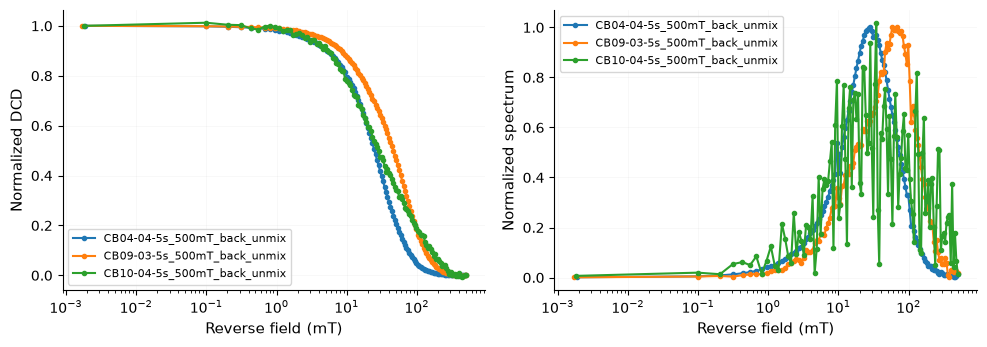

In [43]:
if FILE_PATHS and INPUT_FILES.value:
    raise ValueError('Use FILE_PATHS or the interactive selection, not both.')
CONFIG['field_unit'] = FIELD_UNIT.value
CONFIG['input_signal_unit'] = INPUT_UNIT.value
CONFIG = validate_config(CONFIG,require_model=False)
SAMPLES = load_selected_inputs(FILE_PATHS or list(INPUT_FILES.value), None, CONFIG)
LOADED_PREPROCESS = {k: copy.deepcopy(CONFIG[k]) for k in ['grid_points','smooth','smoothing_s','spectrum_method','field_unit']}
COMPARISON = None
SELECTED_FINAL = None
FINAL_LABEL = None
FINAL_COMPARISON = None
preview_samples(SAMPLES)


## 4. Compare component counts

Set `RUN_COMPARISON=True` to fit several values of K. Comparison results remain in `COMPARISON`; individual candidates can be inspected and adopted in section 7. Bh intervals are specified separately for each K.

`BH_MODE='auto'` estimates bounds from the mean normalized spectrum, with equal log-field intervals as fallback; `manual` uses explicit bounds.

RMSE, AICc and BIC use DCD residuals at measured fields (smoothed DCD if selected), excluding the soft-coupling penalty. Parameter counts include one fitted offset per specimen and account for shared parameters. Soft mode uses nominal parameter counts. Failed candidates are excluded from rankings.


K=1, common Bh intervals (mT): [(0.5, 1000.0)]
[1/3] CB04-04-5s_500mT_back_unmix: independent multi-start
[2/3] CB09-03-5s_500mT_back_unmix: independent multi-start
[3/3] CB10-04-5s_500mT_back_unmix: independent multi-start
K=2, common Bh intervals (mT): [(0.5, 15.0), (20.0, 1000.0)]
[1/3] CB04-04-5s_500mT_back_unmix: independent multi-start
[2/3] CB09-03-5s_500mT_back_unmix: independent multi-start
[3/3] CB10-04-5s_500mT_back_unmix: independent multi-start
K=3, common Bh intervals (mT): [(0.5, 15.0), (20.0, 100.0), (100.0, 1000.0)]
[1/3] CB04-04-5s_500mT_back_unmix: independent multi-start
[2/3] CB09-03-5s_500mT_back_unmix: independent multi-start
[3/3] CB10-04-5s_500mT_back_unmix: independent multi-start
K=4, common Bh intervals (mT): [(0.5, 15.0), (20.0, 55.0), (55.0, 100.0), (100.0, 1000.0)]
[1/3] CB04-04-5s_500mT_back_unmix: independent multi-start
[2/3] CB09-03-5s_500mT_back_unmix: independent multi-start
[3/3] CB10-04-5s_500mT_back_unmix: independent multi-start


,Components,N_observations,N_parameters,RSS_norm,RMSE_norm,AIC,AICc,BIC,Fit_mode,Optimizer_success,Bounds_warnings,Bh_bounds_mT,Criteria_note,Residual_reduction_%,Delta_AICc,Delta_BIC
0,1,360,15,0.047973,0.011544,-3182.361406,-3180.966057,-3124.069846,independent,True,3,"[[0.5, 1000.0]]",heuristic: endpoint normalization; smoothed re...,NaN,779.071510,654.997196
1,2,360,27,0.007008,0.004412,-3850.873640,-3846.319423,-3745.948831,independent,True,5,"[[0.5, 15.0], [20.0, 1000.0]]",heuristic: endpoint normalization; smoothed re...,61.780432,113.718144,33.118210
2,3,360,39,0.005279,0.003829,-3928.817599,-3919.067599,-3777.259542,independent,True,8,"[[0.5, 15.0], [20.0, 100.0], [100.0, 1000.0]]",heuristic: endpoint normalization; smoothed re...,13.202193,40.969969,1.807500
3,4,360,51,0.004317,0.003463,-3977.258347,-3960.037568,-3779.067041,independent,True,9,"[[0.5, 15.0], [20.0, 55.0], [55.0, 100.0], [10...",heuristic: endpoint normalization; smoothed re...,9.571631,0.000000,0.000000


,Sample,Components,RMSE_norm,Optimizer_success,N_observations,N_parameters,RSS_norm,AIC,AICc,BIC
0,CB04-04-5s_500mT_back_unmix,1,0.009334,True,120,5,0.010454,-1111.787724,-1111.261408,-1097.850265
1,CB09-03-5s_500mT_back_unmix,1,0.014665,True,120,5,0.025808,-1003.349789,-1002.823473,-989.412330
2,CB10-04-5s_500mT_back_unmix,1,0.009879,True,120,5,0.011711,-1098.167066,-1097.640750,-1084.229607
3,CB04-04-5s_500mT_back_unmix,2,0.000952,True,120,9,0.000109,-1651.749263,-1650.112899,-1626.661837
4,CB09-03-5s_500mT_back_unmix,2,0.002598,True,120,9,0.000810,-1410.704852,-1409.068489,-1385.617427
5,CB10-04-5s_500mT_back_unmix,2,0.007123,True,120,9,0.006089,-1168.655690,-1167.019327,-1143.568265
6,CB04-04-5s_500mT_back_unmix,3,0.000832,True,120,13,0.000083,-1675.878872,-1672.444910,-1639.641480
7,CB09-03-5s_500mT_back_unmix,3,0.002504,True,120,13,0.000753,-1411.540530,-1408.106568,-1375.303138
8,CB10-04-5s_500mT_back_unmix,3,0.006085,True,120,13,0.004444,-1198.452139,-1195.018177,-1162.214747
9,CB04-04-5s_500mT_back_unmix,4,0.000676,True,120,17,0.000055,-1717.838364,-1711.838364,-1670.451004


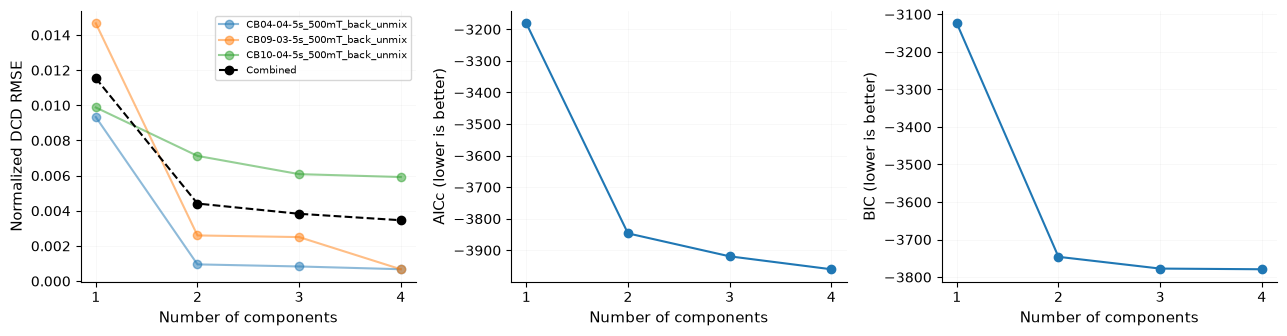

AICc suggestion among converged models: K=4
BIC suggestion among converged models: K=4
No model adopted. Inspect residuals, bounds, convergence and geological plausibility.


In [44]:
RUN_COMPARISON = True
COMPONENT_COUNTS = [1, 2, 3, 4]
BH_MODE = 'manual'  # 'auto' or 'manual'
BOUNDS_BY_K = {
    1: [(0.5, 1000.0)],
    2: [(0.5, 15.0), (20.0, 1000.0)],
    3: [(0.5, 15.0), (20.0, 100.0), (100.0, 1000.0)],
    4: [(0.5, 15.0), (20.0, 55.0), (55.0, 100.0), (100.0, 1000.0)],
}  # EDITABLE EXAMPLES, not preselected physical populations
N_STARTS_COMPARISON = 4

if RUN_COMPARISON and SAMPLES:
    if any(CONFIG[k] != v for k,v in LOADED_PREPROCESS.items()):
        raise ValueError('Preprocessing changed: rerun section 3 first.')
    COMPARISON = compare_component_counts(SAMPLES, CONFIG, COMPONENT_COUNTS,
        BOUNDS_BY_K, BH_MODE, n_starts=N_STARTS_COMPARISON)
    show_comparison(COMPARISON)
elif RUN_COMPARISON:
    print('Load files in section 3 before running the comparison.')
else:
    print('Comparison disabled. Set RUN_COMPARISON=True and execute this cell when ready.')


## 7. Fit selected model

Choose `N_COMPONENTS` in the next cell; its Bh intervals are selected from `BH_BOUNDS_BY_COMPONENT`. Edit the intervals for each model as needed. These bounds are independent of the comparison bounds in section 4.

Fitting replaces the previous selection and clears its bootstrap results. Export is performed separately in section 8.


/tmp/ipykernel_116825/3650578115.py:59: UserWarning: Bh intervals overlap: component labels may be ambiguous. Inspect the fitted centres.
  warnings.warn('Bh intervals overlap: component labels may be ambiguous. Inspect the fitted centres.')


[1/3] CB04-04-5s_500mT_back_unmix: independent multi-start
[2/3] CB09-03-5s_500mT_back_unmix: independent multi-start
[3/3] CB10-04-5s_500mT_back_unmix: independent multi-start


,Sample,Component,Bh_mT,log10_Bh,Bh_mode_mT,DP,Sigma_Egli,q_Egli,p_Egli,P_peak,Amplitude_DCD,DCD_offset,S,Contribution_fraction,Contribution_%,Window_capture_fraction,Bh_min_allowed_mT,Bh_max_allowed_mT,Bound_warning,Contribution_full_model_%
0,CB04-04-5s_500mT_back_unmix,1,14.354005,1.156973,15.953370,0.600000,0.619134,0.75,2.0,0.256399,0.380842,-0.00113,0.75,0.381110,38.111002,0.997734,4.5,18.0,DP near bound; S near lower bound,38.164510
1,CB04-04-5s_500mT_back_unmix,2,28.453068,1.454129,29.983914,0.297640,0.307132,0.75,2.0,0.791704,0.583352,-0.00113,0.75,0.585088,58.508786,0.999999,18.0,80.0,S near lower bound,58.458203
2,CB04-04-5s_500mT_back_unmix,3,83.632188,1.922373,83.632188,0.143302,0.143302,1.00,2.0,0.093823,0.033702,-0.00113,1.00,0.033802,3.380212,1.000000,70.0,1000.0,,3.377287


,Sample,Fit_mode,Fit_objective,Model_version,DCD_offset,RMSE_DCD_target,Optimizer_success,Optimizer_message,N_measured,RMSE_spectrum_measured,RMSE_DCD_normalized,N_components,Input_warnings
0,CB04-04-5s_500mT_back_unmix,independent,DCD measured,Egli_SGG_p2_DCD_v4,-0.00113,0.000696,True,`gtol` termination condition is satisfied.,120,0.013902,0.000696,3,1 upward moment steps


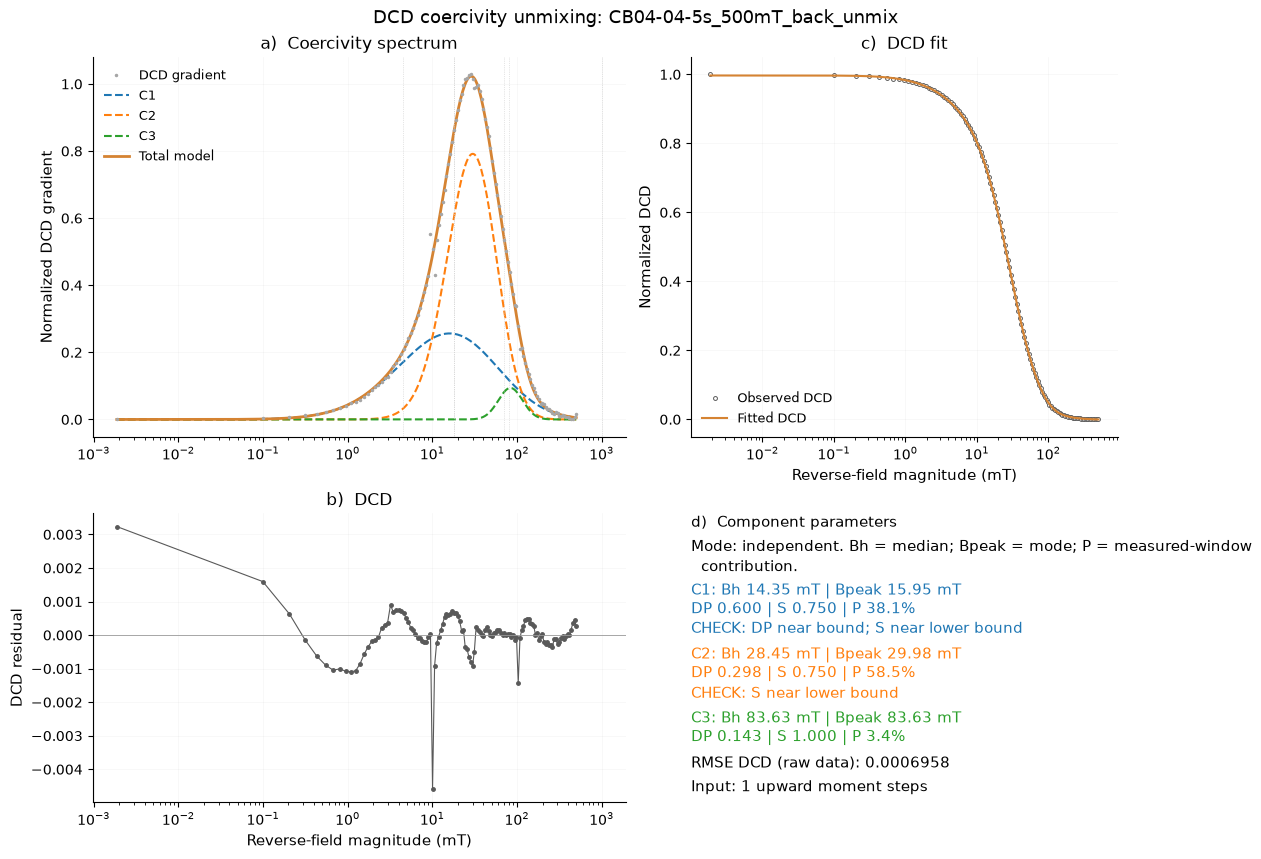

,Sample,Component,Bh_mT,log10_Bh,Bh_mode_mT,DP,Sigma_Egli,q_Egli,p_Egli,P_peak,Amplitude_DCD,DCD_offset,S,Contribution_fraction,Contribution_%,Window_capture_fraction,Bh_min_allowed_mT,Bh_max_allowed_mT,Bound_warning,Contribution_full_model_%
0,CB09-03-5s_500mT_back_unmix,1,4.500487,0.653260,5.001945,0.600000,0.619134,0.75,2.0,0.040575,0.060268,-0.004208,0.75,0.060201,6.020119,0.999940,4.5,18.0,Bh near lower bound; DP near bound; S near low...,6.007622
1,CB09-03-5s_500mT_back_unmix,2,31.593756,1.499601,31.593756,0.444177,0.444177,1.00,2.0,0.543273,0.604872,-0.004208,1.00,0.602152,60.215198,0.996544,18.0,80.0,,60.294947
2,CB09-03-5s_500mT_back_unmix,3,77.550721,1.889586,77.550721,0.223361,0.223361,1.00,2.0,0.603784,0.338049,-0.004208,1.00,0.337647,33.764683,0.999856,70.0,1000.0,,33.697431


,Sample,Fit_mode,Fit_objective,Model_version,DCD_offset,RMSE_DCD_target,Optimizer_success,Optimizer_message,N_measured,RMSE_spectrum_measured,RMSE_DCD_normalized,N_components,Input_warnings
0,CB09-03-5s_500mT_back_unmix,independent,DCD measured,Egli_SGG_p2_DCD_v4,-0.004208,0.00094,True,`gtol` termination condition is satisfied.,120,0.021751,0.00094,3,2 upward moment steps


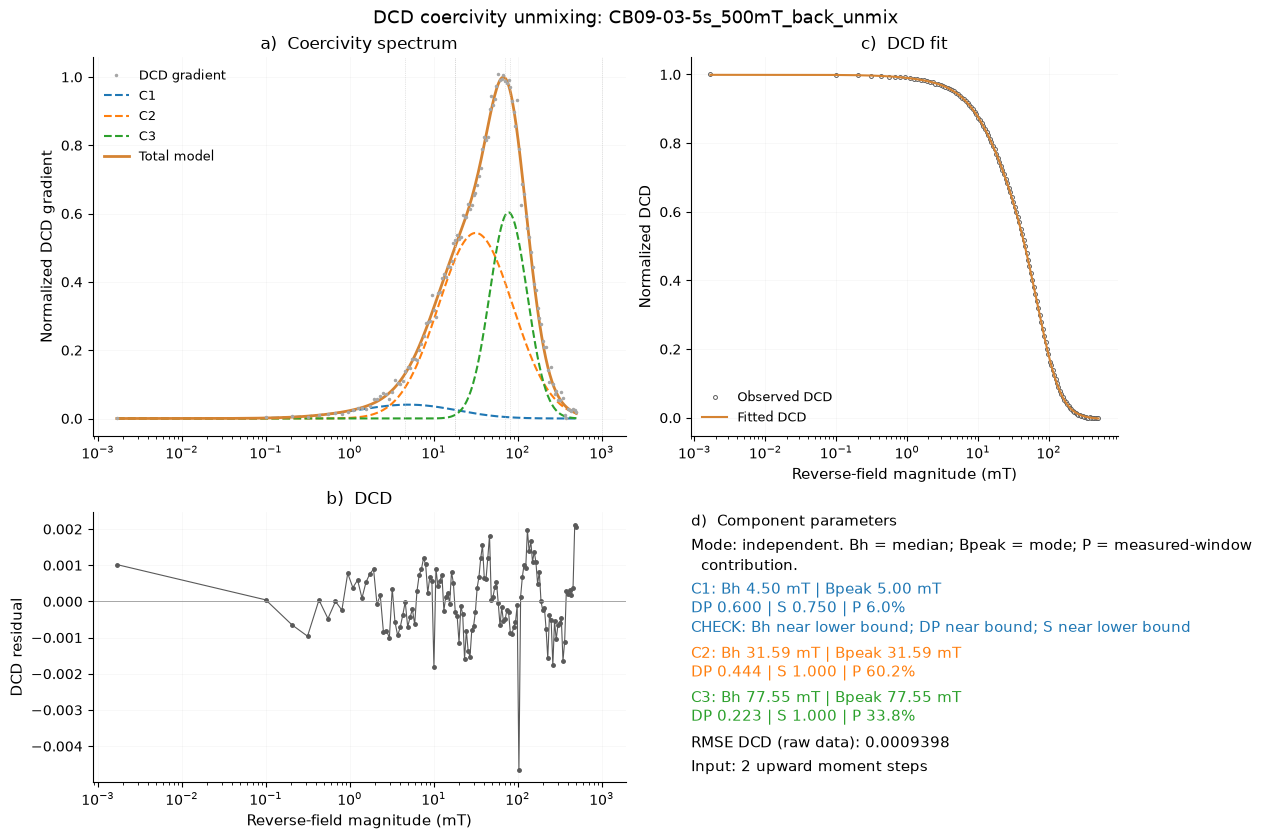

,Sample,Component,Bh_mT,log10_Bh,Bh_mode_mT,DP,Sigma_Egli,q_Egli,p_Egli,P_peak,Amplitude_DCD,DCD_offset,S,Contribution_fraction,Contribution_%,Window_capture_fraction,Bh_min_allowed_mT,Bh_max_allowed_mT,Bound_warning,Contribution_full_model_%
0,CB10-04-5s_500mT_back_unmix,1,4.500000,0.653213,4.697806,0.600000,0.608628,0.83636,2.0,0.075035,0.112615,-0.011624,0.83636,0.111286,11.128594,0.999833,4.5,18.0,Bh near lower bound; DP near bound,11.081260
1,CB10-04-5s_500mT_back_unmix,2,20.900561,1.320158,20.900561,0.408927,0.408927,1.00000,2.0,0.616261,0.631685,-0.011624,1.00000,0.624103,62.410260,0.999628,18.0,80.0,,62.157576
2,CB10-04-5s_500mT_back_unmix,3,126.079960,2.100646,132.951992,0.301427,0.311039,0.75000,2.0,0.364463,0.271964,-0.011624,0.75000,0.264611,26.461146,0.984419,70.0,1000.0,S near lower bound,26.761164


,Sample,Fit_mode,Fit_objective,Model_version,DCD_offset,RMSE_DCD_target,Optimizer_success,Optimizer_message,N_measured,RMSE_spectrum_measured,RMSE_DCD_normalized,N_components,Input_warnings
0,CB10-04-5s_500mT_back_unmix,independent,DCD measured,Egli_SGG_p2_DCD_v4,-0.011624,0.006121,True,`gtol` termination condition is satisfied.,120,0.185023,0.006121,3,26 upward moment steps


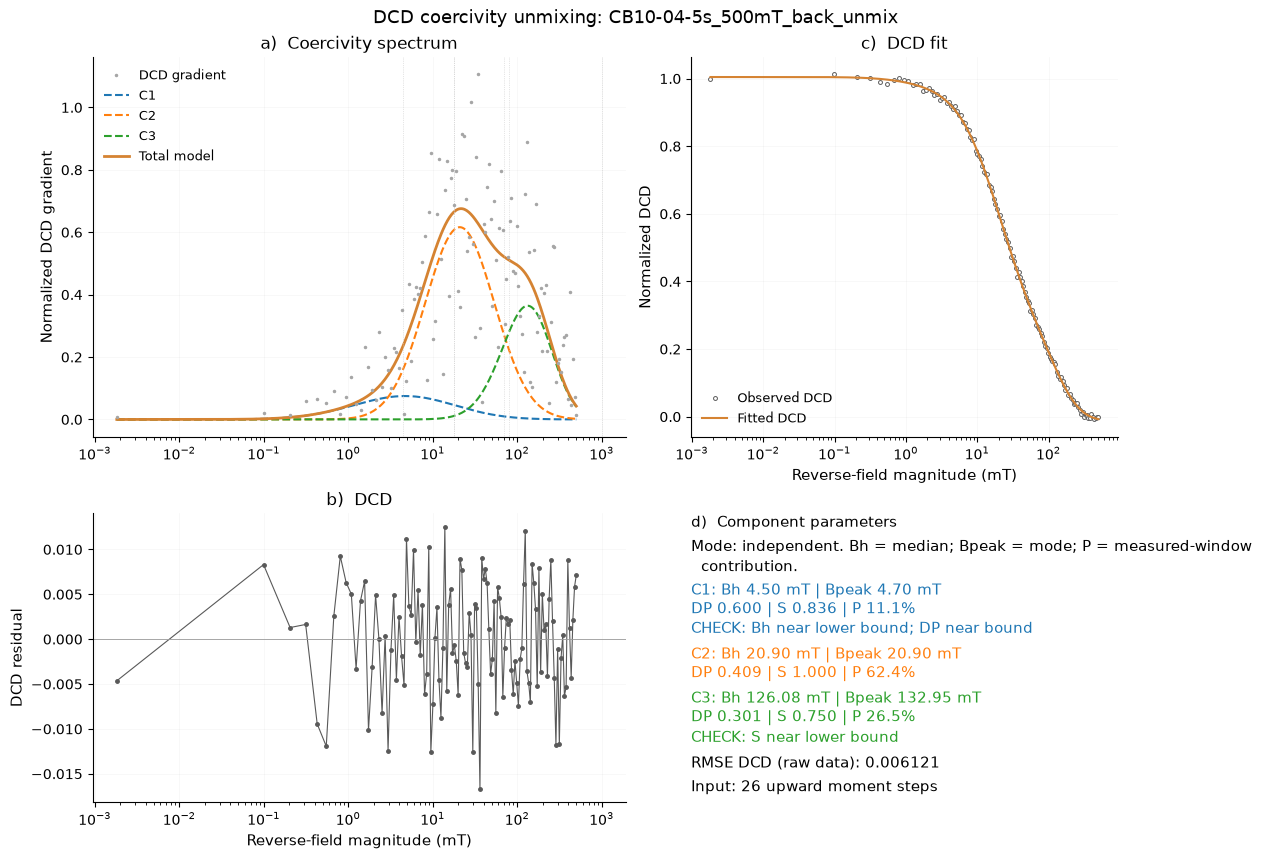

Latest model is now the input to section 7b and section 8. Nothing saved.


In [45]:
RUN_MODEL = True  # execute this cell to calculate/adopt the next model

N_COMPONENTS = 3  # choose the model; edit its Bh intervals below if needed
BH_BOUNDS_BY_COMPONENT = {
    2: [(0.5, 15.0), (20.0, 1000.0)],
    3: [(0.5, 18.0), (18.0, 80.0), (70.0, 1000.0)],
    4: [(0.5, 5.0), (5.0, 40.0), (15.0, 75.0), (100.0, 1000.0)],
    5: [(0.5, 5.0), (5.0, 15.0), (15.0, 75.0), (85.0, 150.0), (100.0, 1000.0)],
}
if N_COMPONENTS not in BH_BOUNDS_BY_COMPONENT:
    raise ValueError(f'No Bh intervals defined for {N_COMPONENTS} components; add them to BH_BOUNDS_BY_COMPONENT.')

MODEL_CONFIG = copy.deepcopy(CONFIG)  # inherits S, DP, smoothing, mode and all common settings
MODEL_CONFIG.update(
    n_components=N_COMPONENTS,
    bh_bounds_mT=copy.deepcopy(BH_BOUNDS_BY_COMPONENT[N_COMPONENTS]),
    n_starts=8,  # keep the chosen refinement multi-start setting
)

if RUN_MODEL:
    # Invalidate the previous selection/uncertainty before attempting another fit.
    # If this attempt fails or is interrupted, an earlier result cannot be saved by mistake.
    SELECTED_FINAL = None
    FINAL_LABEL = None
    FINAL_COMPARISON = None
    if not SAMPLES:
        print('Select files and load them in section 3 first. No fit or export performed.')
    else:
        if any(MODEL_CONFIG[k] != v for k,v in LOADED_PREPROCESS.items()):
            raise ValueError('Preprocessing changed: rerun section 3 first.')
        latest_model = fit_samples(SAMPLES,MODEL_CONFIG)
        label = 'latest manual model'        
        validate_selected_fit_inputs(latest_model,SAMPLES,CONFIG)
        SELECTED_FINAL = copy.deepcopy(latest_model)
        clear_bootstrap(SELECTED_FINAL,status='not calculated for this model')
        FINAL_LABEL = label
        FINAL_COMPARISON = copy.deepcopy(COMPARISON)
        show_fits(SELECTED_FINAL)
        print('Latest model is now the input to section 7b and section 8. Nothing saved.')
else:
    print('No new model calculated. The last successfully selected model remains in memory.')


## 7b. Bootstrap (optional)

`CALCULATE_UNCERTAINTY=True` enables bootstrap analysis for the selected model. Defaults: **200 refits**, **95% percentile intervals**, and **15-point circular moving residual blocks** (Künsch, 1989).

Centered residuals from raw normalized DCD are resampled onto the fitted DCD. When smoothing is enabled, it is reapplied before refitting. Endpoint normalization, K, bounds, model symmetry and coupling are retained. Each replicate starts at the selected solution, with the reference offset re-estimated; independent samples are resampled separately.

Intervals cover Bh, DP, S, contributions, amplitudes and offsets. They are conditional on the selected model, bounds, preprocessing and local solution. Curve bands are pointwise. Nonconverged refits are excluded; intervals require at least 80% acceptance and 20 successful refits.

This step updates uncertainty only, without changing fitted parameters or exporting files. Refit the model to reset the bootstrap; rerun this section if needed.


/tmp/ipykernel_116825/3650578115.py:59: UserWarning: Bh intervals overlap: component labels may be ambiguous. Inspect the fitted centres.
  warnings.warn('Bh intervals overlap: component labels may be ambiguous. Inspect the fitted centres.')


Bootstrap 20/200: CB04-04-5s_500mT_back_unmix 20 accepted, CB09-03-5s_500mT_back_unmix 20 accepted, CB10-04-5s_500mT_back_unmix 20 accepted
Bootstrap 40/200: CB04-04-5s_500mT_back_unmix 40 accepted, CB09-03-5s_500mT_back_unmix 40 accepted, CB10-04-5s_500mT_back_unmix 40 accepted
Bootstrap 60/200: CB04-04-5s_500mT_back_unmix 60 accepted, CB09-03-5s_500mT_back_unmix 60 accepted, CB10-04-5s_500mT_back_unmix 60 accepted
Bootstrap 80/200: CB04-04-5s_500mT_back_unmix 80 accepted, CB09-03-5s_500mT_back_unmix 80 accepted, CB10-04-5s_500mT_back_unmix 80 accepted
Bootstrap 100/200: CB04-04-5s_500mT_back_unmix 100 accepted, CB09-03-5s_500mT_back_unmix 100 accepted, CB10-04-5s_500mT_back_unmix 100 accepted
Bootstrap 120/200: CB04-04-5s_500mT_back_unmix 120 accepted, CB09-03-5s_500mT_back_unmix 120 accepted, CB10-04-5s_500mT_back_unmix 120 accepted
Bootstrap 140/200: CB04-04-5s_500mT_back_unmix 140 accepted, CB09-03-5s_500mT_back_unmix 140 accepted, CB10-04-5s_500mT_back_unmix 140 accepted
Bootstra

,Sample,Component,Bootstrap_successes,Bootstrap_requested,Bootstrap_CI_percent,Bootstrap_CI_available,Bh_mT_bootstrap_median,Bh_mT_CI_low,Bh_mT_CI_high,DP_bootstrap_median,...,Contribution_full_model_%_bootstrap_median,Contribution_full_model_%_CI_low,Contribution_full_model_%_CI_high,Amplitude_DCD_bootstrap_median,Amplitude_DCD_CI_low,Amplitude_DCD_CI_high,DCD_offset_bootstrap_median,DCD_offset_CI_low,DCD_offset_CI_high,S_fixed
0,CB04-04-5s_500mT_back_unmix,1,200,200,95.0,True,14.161390,12.308779,15.065623,0.599863,...,38.059848,33.375696,41.310516,0.379939,0.332797,0.412075,-0.001007,-0.001946,-0.000183,False
1,CB04-04-5s_500mT_back_unmix,2,200,200,95.0,True,28.681273,27.293455,30.173130,0.298988,...,58.951035,53.131518,64.488956,0.588004,0.529716,0.643044,-0.001007,-0.001946,-0.000183,False
2,CB04-04-5s_500mT_back_unmix,3,200,200,95.0,True,83.641372,73.657508,92.010965,0.135907,...,3.015885,1.065740,7.233311,0.030074,0.010628,0.072086,-0.001007,-0.001946,-0.000183,False


{'sample': 'CB04-04-5s_500mT_back_unmix',
 'requested': 200,
 'successful_refits': 200,
 'failed_refits': 0,
 'success_fraction': 1.0,
 'intervals_available': True,
 'required_successes': 160,
 'block_length_used': 15,
 'component_records_with_flags_fraction': 0.66,
 'warnings': ['Over 20% of bootstrap component records have boundary/tail flags; inspect constraints.']}

,Sample,Component,Bootstrap_successes,Bootstrap_requested,Bootstrap_CI_percent,Bootstrap_CI_available,Bh_mT_bootstrap_median,Bh_mT_CI_low,Bh_mT_CI_high,DP_bootstrap_median,...,Contribution_full_model_%_bootstrap_median,Contribution_full_model_%_CI_low,Contribution_full_model_%_CI_high,Amplitude_DCD_bootstrap_median,Amplitude_DCD_CI_low,Amplitude_DCD_CI_high,DCD_offset_bootstrap_median,DCD_offset_CI_low,DCD_offset_CI_high,S_fixed
0,CB09-03-5s_500mT_back_unmix,1,200,200,95.0,True,4.500000,4.500000,6.091457,0.600000,...,5.922673,4.885100,7.310338,0.059444,0.048938,0.073207,-0.004243,-0.006238,-0.002347,False
1,CB09-03-5s_500mT_back_unmix,2,200,200,95.0,True,31.876870,29.553336,33.843853,0.445612,...,60.740991,56.775557,66.856661,0.609559,0.568234,0.670132,-0.004243,-0.006238,-0.002347,False
2,CB09-03-5s_500mT_back_unmix,3,200,200,95.0,True,77.469195,75.931768,78.540018,0.222479,...,33.225871,28.438186,37.529907,0.333429,0.285033,0.375950,-0.004243,-0.006238,-0.002347,False


{'sample': 'CB09-03-5s_500mT_back_unmix',
 'requested': 200,
 'successful_refits': 200,
 'failed_refits': 0,
 'success_fraction': 1.0,
 'intervals_available': True,
 'required_successes': 160,
 'block_length_used': 15,
 'component_records_with_flags_fraction': 0.335,
 'warnings': ['Over 20% of bootstrap component records have boundary/tail flags; inspect constraints.']}

,Sample,Component,Bootstrap_successes,Bootstrap_requested,Bootstrap_CI_percent,Bootstrap_CI_available,Bh_mT_bootstrap_median,Bh_mT_CI_low,Bh_mT_CI_high,DP_bootstrap_median,...,Contribution_full_model_%_bootstrap_median,Contribution_full_model_%_CI_low,Contribution_full_model_%_CI_high,Amplitude_DCD_bootstrap_median,Amplitude_DCD_CI_low,Amplitude_DCD_CI_high,DCD_offset_bootstrap_median,DCD_offset_CI_low,DCD_offset_CI_high,S_fixed
0,CB10-04-5s_500mT_back_unmix,1,200,200,95.0,True,4.500000,4.500000,17.999987,0.600000,...,11.505595,7.900086,48.927505,0.116790,0.080029,0.494143,-0.012483,-0.02191,-0.00686,False
1,CB10-04-5s_500mT_back_unmix,2,200,200,95.0,True,20.446753,18.000000,23.562416,0.392249,...,59.424979,24.306557,71.771795,0.603391,0.247784,0.728437,-0.012483,-0.02191,-0.00686,False
2,CB10-04-5s_500mT_back_unmix,3,200,200,95.0,True,122.707770,101.316807,145.274189,0.303869,...,28.229955,18.494325,38.511175,0.287123,0.187760,0.394737,-0.012483,-0.02191,-0.00686,False


{'sample': 'CB10-04-5s_500mT_back_unmix',
 'requested': 200,
 'successful_refits': 200,
 'failed_refits': 0,
 'success_fraction': 1.0,
 'intervals_available': True,
 'required_successes': 160,
 'block_length_used': 15,
 'component_records_with_flags_fraction': 0.6233333333333333,
 'warnings': ['Over 20% of bootstrap component records have boundary/tail flags; inspect constraints.']}

,Sample,Component,Bh_mT,log10_Bh,Bh_mode_mT,DP,Sigma_Egli,q_Egli,p_Egli,P_peak,...,Contribution_full_model_%_bootstrap_median,Contribution_full_model_%_CI_low,Contribution_full_model_%_CI_high,Amplitude_DCD_bootstrap_median,Amplitude_DCD_CI_low,Amplitude_DCD_CI_high,DCD_offset_bootstrap_median,DCD_offset_CI_low,DCD_offset_CI_high,S_fixed
0,CB04-04-5s_500mT_back_unmix,1,14.354005,1.156973,15.953370,0.600000,0.619134,0.75,2.0,0.256399,...,38.059848,33.375696,41.310516,0.379939,0.332797,0.412075,-0.001007,-0.001946,-0.000183,False
1,CB04-04-5s_500mT_back_unmix,2,28.453068,1.454129,29.983914,0.297640,0.307132,0.75,2.0,0.791704,...,58.951035,53.131518,64.488956,0.588004,0.529716,0.643044,-0.001007,-0.001946,-0.000183,False
2,CB04-04-5s_500mT_back_unmix,3,83.632188,1.922373,83.632188,0.143302,0.143302,1.00,2.0,0.093823,...,3.015885,1.065740,7.233311,0.030074,0.010628,0.072086,-0.001007,-0.001946,-0.000183,False


,Sample,Fit_mode,Fit_objective,Model_version,DCD_offset,RMSE_DCD_target,Optimizer_success,Optimizer_message,N_measured,RMSE_spectrum_measured,RMSE_DCD_normalized,N_components,Input_warnings
0,CB04-04-5s_500mT_back_unmix,independent,DCD measured,Egli_SGG_p2_DCD_v4,-0.00113,0.000696,True,`gtol` termination condition is satisfied.,120,0.013902,0.000696,3,1 upward moment steps


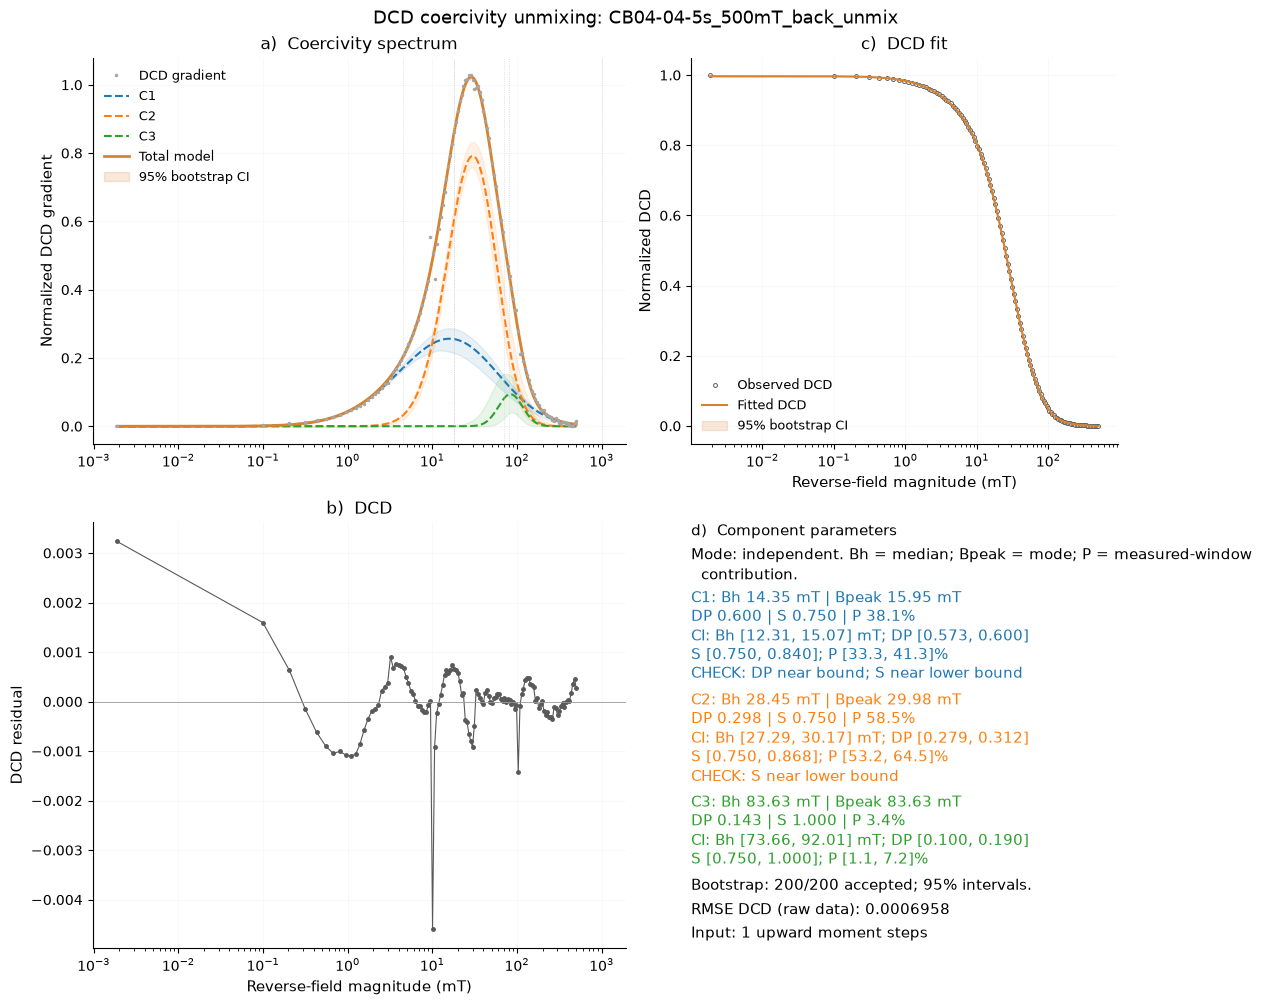

,Sample,Component,Bh_mT,log10_Bh,Bh_mode_mT,DP,Sigma_Egli,q_Egli,p_Egli,P_peak,...,Contribution_full_model_%_bootstrap_median,Contribution_full_model_%_CI_low,Contribution_full_model_%_CI_high,Amplitude_DCD_bootstrap_median,Amplitude_DCD_CI_low,Amplitude_DCD_CI_high,DCD_offset_bootstrap_median,DCD_offset_CI_low,DCD_offset_CI_high,S_fixed
0,CB09-03-5s_500mT_back_unmix,1,4.500487,0.653260,5.001945,0.600000,0.619134,0.75,2.0,0.040575,...,5.922673,4.885100,7.310338,0.059444,0.048938,0.073207,-0.004243,-0.006238,-0.002347,False
1,CB09-03-5s_500mT_back_unmix,2,31.593756,1.499601,31.593756,0.444177,0.444177,1.00,2.0,0.543273,...,60.740991,56.775557,66.856661,0.609559,0.568234,0.670132,-0.004243,-0.006238,-0.002347,False
2,CB09-03-5s_500mT_back_unmix,3,77.550721,1.889586,77.550721,0.223361,0.223361,1.00,2.0,0.603784,...,33.225871,28.438186,37.529907,0.333429,0.285033,0.375950,-0.004243,-0.006238,-0.002347,False


,Sample,Fit_mode,Fit_objective,Model_version,DCD_offset,RMSE_DCD_target,Optimizer_success,Optimizer_message,N_measured,RMSE_spectrum_measured,RMSE_DCD_normalized,N_components,Input_warnings
0,CB09-03-5s_500mT_back_unmix,independent,DCD measured,Egli_SGG_p2_DCD_v4,-0.004208,0.00094,True,`gtol` termination condition is satisfied.,120,0.021751,0.00094,3,2 upward moment steps


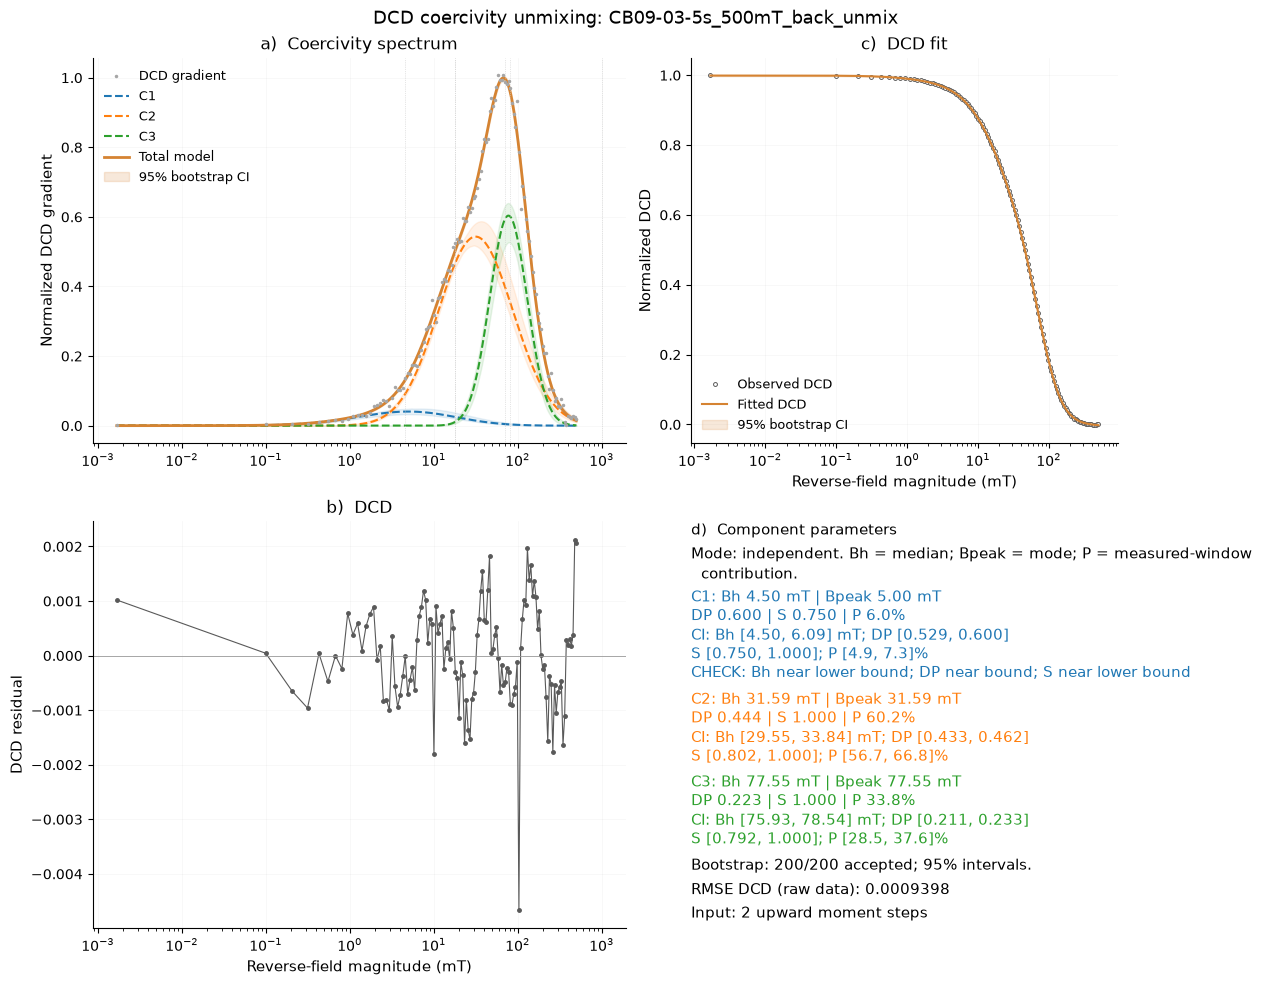

,Sample,Component,Bh_mT,log10_Bh,Bh_mode_mT,DP,Sigma_Egli,q_Egli,p_Egli,P_peak,...,Contribution_full_model_%_bootstrap_median,Contribution_full_model_%_CI_low,Contribution_full_model_%_CI_high,Amplitude_DCD_bootstrap_median,Amplitude_DCD_CI_low,Amplitude_DCD_CI_high,DCD_offset_bootstrap_median,DCD_offset_CI_low,DCD_offset_CI_high,S_fixed
0,CB10-04-5s_500mT_back_unmix,1,4.500000,0.653213,4.697806,0.600000,0.608628,0.83636,2.0,0.075035,...,11.505595,7.900086,48.927505,0.116790,0.080029,0.494143,-0.012483,-0.02191,-0.00686,False
1,CB10-04-5s_500mT_back_unmix,2,20.900561,1.320158,20.900561,0.408927,0.408927,1.00000,2.0,0.616261,...,59.424979,24.306557,71.771795,0.603391,0.247784,0.728437,-0.012483,-0.02191,-0.00686,False
2,CB10-04-5s_500mT_back_unmix,3,126.079960,2.100646,132.951992,0.301427,0.311039,0.75000,2.0,0.364463,...,28.229955,18.494325,38.511175,0.287123,0.187760,0.394737,-0.012483,-0.02191,-0.00686,False


,Sample,Fit_mode,Fit_objective,Model_version,DCD_offset,RMSE_DCD_target,Optimizer_success,Optimizer_message,N_measured,RMSE_spectrum_measured,RMSE_DCD_normalized,N_components,Input_warnings
0,CB10-04-5s_500mT_back_unmix,independent,DCD measured,Egli_SGG_p2_DCD_v4,-0.011624,0.006121,True,`gtol` termination condition is satisfied.,120,0.185023,0.006121,3,26 upward moment steps


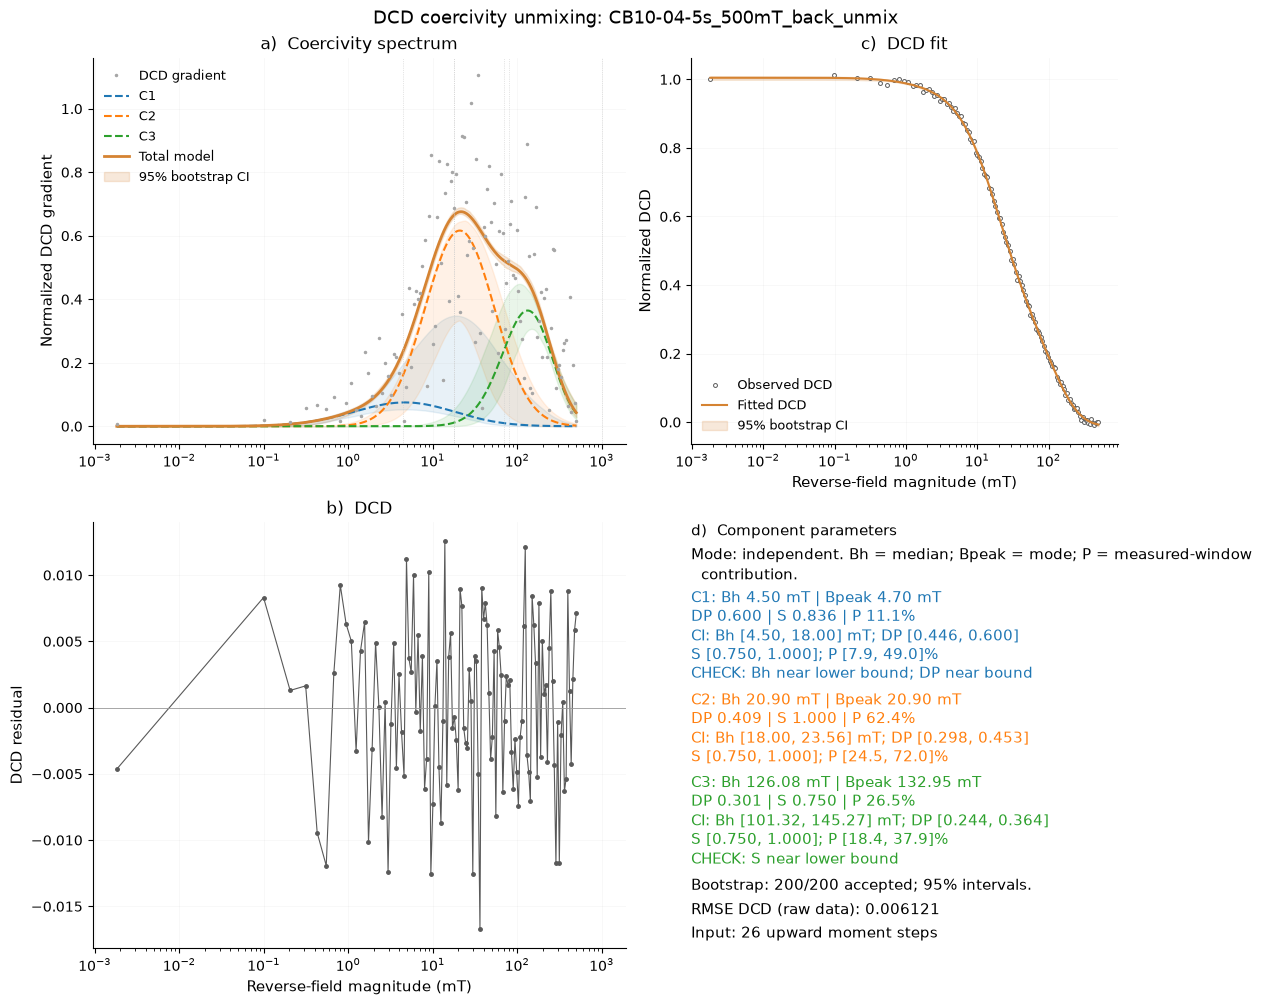

Uncertainty calculated in memory. Execute section 8 only when ready to save.


In [46]:
CALCULATE_UNCERTAINTY = True  # default ON; False skips/removes uncertainty
N_BOOTSTRAP = 200
BOOTSTRAP_CI = 95.0
BOOTSTRAP_BLOCK_LENGTH = 15  # measured DCD observations, not interpolated grid points
BOOTSTRAP_RANDOM_SEED = 50042
BOOTSTRAP_MAX_NFEV = 2000
BOOTSTRAP_MIN_SUCCESS_FRACTION = 0.80
BOOTSTRAP_MIN_SUCCESSES = 20
BOOTSTRAP_PROGRESS_EVERY = 20

if SELECTED_FINAL is None:
    print('Select and review the final result in section 7 first. No bootstrap or files created.')
elif not CALCULATE_UNCERTAINTY:
    clear_bootstrap(SELECTED_FINAL,status='disabled by user')
    print('Bootstrap disabled. The selected point estimates remain available for export.')
else:
    validate_selected_fit_inputs(SELECTED_FINAL,SAMPLES,CONFIG)
    # Assignment occurs only after completion: an interrupted calculation keeps the previous snapshot.
    SELECTED_FINAL = bootstrap_uncertainty(SELECTED_FINAL,
        n_bootstrap=N_BOOTSTRAP, ci=BOOTSTRAP_CI, block_length=BOOTSTRAP_BLOCK_LENGTH,
        random_seed=BOOTSTRAP_RANDOM_SEED, max_nfev=BOOTSTRAP_MAX_NFEV,
        min_success_fraction=BOOTSTRAP_MIN_SUCCESS_FRACTION,
        min_successes=BOOTSTRAP_MIN_SUCCESSES,progress_every=BOOTSTRAP_PROGRESS_EVERY)
    for fit in SELECTED_FINAL:
        display(fit['uncertainty']['summary'])
        display(fit['uncertainty']['diagnostics'])
    show_fits(SELECTED_FINAL)
    print('Uncertainty calculated in memory. Execute section 8 only when ready to save.')


## 8. Export results

Export creates two folders in `OUTPUT_PARENT`:

- `figures/`: PDF and PNG figures.
- `fit_data/`: model JSON, fitted parameters, measured and model curves, bootstrap results and comparison data.

Outputs use the input basename by default. `OUTPUT_NAMES` changes individual basenames; `OUTPUT_TAG` appends a fit label. Existing results are retained with `__v02`, `__v03`, etc., unless `OVERWRITE_EXISTING=True` (which replaces the corresponding base and its associated files).

Example: `Sample_A.txt` → `figures/Sample_A.pdf` and `fit_data/Sample_A_fit.json`. No specimen/run subdirectories are created.

A saved fit can be loaded without the raw measurement:

`fit = load_saved_fit(Path('/path/to/fit_data/Sample_A_fit.json'))`

`make_sample_summary_figure(fit)` recreates the summary figure. CSV exports contain curves and parameters for other layouts.


In [47]:
SAVE_FINAL = True
OUTPUT_NAMES = {}  # optional: {'Sample_A.txt': 'chosen_name'}; otherwise input basename
OUTPUT_TAG = ''    # optional: 'alternative_fit'; otherwise no added label
OVERWRITE_EXISTING = True  # False preserves earlier results using __v02, __v03, ...
if SAVE_FINAL and SELECTED_FINAL is not None:
    validate_selected_fit_inputs(SELECTED_FINAL,SAMPLES,CONFIG)
    OUTPUT_PARENT=explicit_output_parent()
    destination=export_results(SELECTED_FINAL,PROJECT_ROOT,output_parent=OUTPUT_PARENT,
        output_names=OUTPUT_NAMES,output_tag=OUTPUT_TAG,overwrite=OVERWRITE_EXISTING,
        selection_label=FINAL_LABEL,comparison=FINAL_COMPARISON)
    print('Figures:',destination/'figures')
    print('Replotting data:',destination/'fit_data')
elif SAVE_FINAL:
    print('Calculate a model in section 7 before saving. No files written.')
else:
    print('Final export disabled. No results written.')


CB04-04-5s_500mT_back_unmix.back -> figures/CB04-04-5s_500mT_back_unmix.pdf / .png; fit_data/CB04-04-5s_500mT_back_unmix_*
CB09-03-5s_500mT_back_unmix.back -> figures/CB09-03-5s_500mT_back_unmix.pdf / .png; fit_data/CB09-03-5s_500mT_back_unmix_*
CB10-04-5s_500mT_back_unmix.back -> figures/CB10-04-5s_500mT_back_unmix.pdf / .png; fit_data/CB10-04-5s_500mT_back_unmix_*
Figures: /home/pablo/Investigacion_IA/Proyectos/26_Paper_Gabros/Paper_Clean_v01/data/DCD_curves/processed_dcd/DCD_unmix_results/figures
Replotting data: /home/pablo/Investigacion_IA/Proyectos/26_Paper_Gabros/Paper_Clean_v01/data/DCD_curves/processed_dcd/DCD_unmix_results/fit_data


## 9. Replot saved results (optional)

Set `SAVED_FIT_JSON` to a `fit_data/*_fit.json` file. The saved curves, parameters and bootstrap bands can be replotted without refitting. Custom plots can use the exported CSVs or `RESTORED_FIT`.


In [ ]:
SAVED_FIT_JSON = None  # e.g. Path('/path/to/DCD_unmix_results/fit_data/Sample_A_fit.json')
if SAVED_FIT_JSON is not None:
    RESTORED_FIT = load_saved_fit(Path(SAVED_FIT_JSON).expanduser())
    display(RESTORED_FIT['table'])
    fig = make_sample_summary_figure(RESTORED_FIT)
    plt.show()
    plt.close(fig)


## References

**SGG and coercivity unmixing**

- Egli, R. (2003). Analysis of the field dependence of remanent magnetization curves. *JGR Solid Earth*, **108**(B2), 2081. https://doi.org/10.1029/2002JB002023
- Egli, R. (2004a). Characterization of individual rock magnetic components by analysis of remanence curves, 1. Unmixing natural sediments. *Studia Geophys. Geod.*, **48**, 391–446. https://doi.org/10.1023/B:SGEG.0000020839.45304.6d
- Egli, R. (2004b). Characterization of individual rock magnetic components by analysis of remanence curves, 2. Fundamental properties of coercivity distributions. *Phys. Chem. Earth*, **29**, 851–867. https://doi.org/10.1016/j.pce.2004.04.001
- Egli, R. (2004c). Characterization of individual rock magnetic components by analysis of remanence curves, 3. Bacterial magnetite and natural processes in lakes. *Phys. Chem. Earth*, **29**, 869–884. https://doi.org/10.1016/j.pce.2004.03.010

**Related methods**

- Kruiver, P. P., Dekkers, M. J., & Heslop, D. (2001). *Earth Planet. Sci. Lett.*, **189**, 269–276. https://doi.org/10.1016/S0012-821X(01)00367-3
- Heslop, D., Dekkers, M. J., Kruiver, P. P., & van Oorschot, I. H. M. (2002). *Geophys. J. Int.*, **148**, 58–64. https://doi.org/10.1046/j.0956-540x.2001.01558.x
- Maxbauer, D. P., Feinberg, J. M., & Fox, D. L. (2016). MAX UnMix. *Comput. Geosci.*, **95**, 140–145. https://doi.org/10.1016/j.cageo.2016.07.009

## Implementation

Adapted from `DCD_unmixing_joint.ipynb`. DCD fitting uses `scipy.optimize.least_squares` with bounded multi-start optimization, optional parameter coupling and residual bootstrap. Exports include settings, software versions, file hashes and model arrays.
